# Introduction to Machine Learning -- MC886A/MO444A
# Assignment 3 - Neural Networks, Inductive Bias and Distribution Shift

**Professor:** Marcelo da Silva Reis

**PED:** Heigon Soldera

In [1]:
import sys
import ipykernel

print("Python:", sys.version)
print("Executável:", sys.executable)
print("ipykernel:", ipykernel.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Executável: /usr/bin/python3
ipykernel: 6.17.1


In [2]:
# Enter your name and RA number below.
print("Ana Carolina de Almeida Cardoso", "|", "246914")
print("Francisco Vinicius Sousa Guedes", "|", "260440")
print("Pedro Damasceno Vasconcellos", "|", "260640")

Ana Carolina de Almeida Cardoso | 246914
Francisco Vinicius Sousa Guedes | 260440
Pedro Damasceno Vasconcellos | 260640


---

## Objective

In Assignment 2 you saw that the model selected by cross-validation on the training distribution is not
necessarily the most robust one when the test distribution changes. There, the assumption we varied was the
**penalty** of a linear model. In this assignment we vary the **architecture**.

A multilayer perceptron (MLP) and a convolutional neural network (CNN) can both fit a training set almost
perfectly, but they do it under different assumptions about the input, their **inductive biases**:
- an MLP gives every pixel position its own weight and knows nothing about which pixels are neighbors;
- a CNN detects local patterns with small filters that are shared across all positions, and combines them
  hierarchically.

When several hypotheses explain the training data equally well, these assumptions decide which one the network
learns, and the difference only shows up when the test distribution changes. For example, a classifier of
histopathology images can recognize a type of tissue from the shape and the arrangement of its cells, which are the
same in every hospital, or from the exact colors produced by the staining protocol of the hospital where the
training images were acquired. Both solutions fit the training set, but only one of them survives a new hospital.

The goal of this assignment is to test, with controlled experiments, which structural assumptions and which training
choices help a neural network generalize to a clinical center it has never seen.

### Guidelines

> Please read these guidelines carefully.

1. Answers can be written in English or Portuguese.

2. Use data visualization as a primary tool for understanding. Inspect the training data, the transformed inputs, and
   model behavior. When an assumption is uncertain, verify it empirically through plots.

3. The provided code serves as a reference. Modifications are allowed, including changes to functions and the
   introduction of new components. Code clarity and organization are required. The hands-on of Lecture 18 (Deep
   Learning with PyTorch) contains reference implementations of the training loop, of an MLP, of a CNN and of data
   augmentation.

4. We recommend running this notebook on a GPU, for example on Google Colab (GPU runtime) or on a local GPU.

5. The use of generative AI tools (e.g., ChatGPT, GitHub Copilot, DeepSeek, LLaMA) is permitted strictly for
   **implementation support**. Their use for interpreting, analyzing, or discussing experimental results is
   discouraged. Submissions must include:
   - A declaration of which models were used.
   - The prompts that generated any incorporated code.

6. Do not hesitate to reach out to the PED/PAD via Discord.

### Experiment structure

Each experiment must follow the structure below:

1. **Question**: the empirical question guiding the exploration.
2. **Hypothesis**: a falsifiable answer to the question that makes a concrete, measurable prediction.
3. **Design**: justify why the proposed experiment can test the hypothesis. Focus on the reasoning, not on how the
   code works.
4. **Results**: run the experiment and report the metrics.
5. **Discussion**: interpret the results in terms of the hypothesis. Explicitly state whether the results support or
   contradict it, and why.

A hypothesis must be **falsifiable**: the proposed experiment must be capable of providing evidence *against* it.
Statements such as "the model is complex enough" or "the features are informative" do not qualify.

A negative result is not a failure: a well-reasoned experiment that contradicts the hypothesis is graded as highly as
one that confirms it, provided the interpretation is honest and coherent.

For Experiment 1, the question and hypothesis are given. Your task is to complete the missing code, write the design
justification, and discuss the results.
For Experiments 2-4, only the question is given. You must state the hypothesis and discuss the results; in
Experiments 2 and 3 you also justify the design, and in Experiment 4 you choose and evaluate the final model.

### Evaluation protocol

Throughout this assignment, **ID** (*in-distribution*) refers to patches from the same clinical center as the training
set, and **OOD** (*out-of-distribution*) to patches from a different center, which the model never sees during
training.

- **Model selection** (number of epochs, hyperparameters, early stopping, choice of the final model) uses only the
  **ID validation** split.
- The **OOD validation** split is used to *measure* the generalization gap in Experiments 1-4, never to choose
  hyperparameters or models.
- The **OOD test** split is used **only once**, at the end of Experiment 4. Do not look at its images or metrics
  before that.

In [3]:
import copy
import os
import random
import time
import urllib.request

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import balanced_accuracy_score, confusion_matrix

import matplotlib.pyplot as plt
from IPython.display import display

# ── Reproducibility ────────────────────────────────────────────────────────────
# Do not change this seed. Re-run the notebook from scratch before submitting.
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.backends.cudnn.deterministic = True   # reproducible results on the GPU
torch.backends.cudnn.benchmark = False

DEVICE: str = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


---

## Dataset — PathMNIST

Histopathology is the study of thin sections of tissue under a microscope, often to detect disease. The most common
technique stains the section with hematoxylin and eosin (H&E): hematoxylin colors the cell nuclei purple-blue, and
eosin colors the cytoplasm and the extracellular matrix pink, so the pathologist can tell the structures apart.

We use **PathMNIST**, from the [MedMNIST v2](https://medmnist.com/) benchmark, in its 64×64 version. Each sample is a
64×64 RGB patch of an H&E-stained section of colorectal tissue, labeled with one of **9 tissue classes**:

| Label | Tissue |
|---|---|
| 0 | adipose |
| 1 | background |
| 2 | debris |
| 3 | lymphocytes |
| 4 | mucus |
| 5 | smooth muscle |
| 6 | normal colon mucosa |
| 7 | cancer-associated stroma |
| 8 | colorectal adenocarcinoma epithelium |

The patches come from two datasets of the same study (Kather et al., 2019):
- the training and validation patches come from **NCT-CRC-HE-100K**;
- the test patches come from **CRC-VAL-HE-7K**, acquired at a **different clinical center**, with other patients.

Each center has its own staining protocol, scanner and population of patients, so the patches of the new center
differ from the training ones in ways that have nothing to do with the tissue class.

We use the following splits:

| Split | Source | Patches | Role in this assignment |
|---|---|---|---|
| `train` | NCT-CRC-HE-100K | 89,996 | Training |
| `id_val` | NCT-CRC-HE-100K | 10,004 | **ID validation**: early stopping and model selection |
| `ood_val` | CRC-VAL-HE-7K, first half | 3,590 | **OOD validation**: measures the generalization gap |
| `ood_test` | CRC-VAL-HE-7K, second half | 3,590 | **OOD test**: used only once, at the end of Experiment 4 |

The `id_val` patches were drawn at random from the same dataset as the training patches. The official test set of
PathMNIST is split in two halves, stratified by class, with the seed of this notebook. The two halves may contain
patches of the same patients, so they are not fully independent: `ood_test` protects the final result against
choices made *because* a model did well on `ood_val`, but not against everything the two halves have in common.

**Metrics.** We report the accuracy and the **balanced accuracy**, the mean of the recalls of the 9 classes
(`sklearn.metrics.balanced_accuracy_score`). Unlike the accuracy, the balanced accuracy does not change when only
the proportions of the classes change, which will matter in Experiment 4. The **ID–OOD gap**, the balanced accuracy
on `id_val` minus the balanced accuracy on `ood_val`, is the main measure of generalization to the new center.

The next cell downloads the 64×64 version of PathMNIST (about 1 GB, only once) from the
[MedMNIST repository on Zenodo](https://zenodo.org/records/10519652). Alternatively, you can download the data of this
assignment from our Google Classroom page: place the file `pathmnist_64.npz` in a folder named `data`, inside the
working directory of the notebook (on Colab, `/content/data`), and the cell will not download it again. You can also
install the `medmnist` package and use `medmnist.PathMNIST(split=..., size=64, download=True)`.

In [4]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "pathmnist_64.npz")
DATA_URL = "https://zenodo.org/records/10519652/files/pathmnist_64.npz"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):                    # download only once
    print("Downloading PathMNIST 64x64 (about 1 GB)...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

CLASSES = ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle",
           "normal colon mucosa", "cancer-associated stroma", "colorectal adenocarcinoma epithelium"]

with np.load(DATA_PATH) as f:
    # Images stay as uint8 (N, 3, 64, 64) to save memory; they are converted to float one batch at a time.
    X_train = torch.from_numpy(f["train_images"]).permute(0, 3, 1, 2).contiguous()
    y_train = torch.from_numpy(f["train_labels"]).long().squeeze(1)
    X_id_val = torch.from_numpy(f["val_images"]).permute(0, 3, 1, 2).contiguous()
    y_id_val = torch.from_numpy(f["val_labels"]).long().squeeze(1)
    X_external = torch.from_numpy(f["test_images"]).permute(0, 3, 1, 2).contiguous()
    y_external = torch.from_numpy(f["test_labels"]).long().squeeze(1)

In [5]:
def stratified_split(y: torch.Tensor, fraction: float, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    # Splits the indices of y in two parts, with `fraction` of each class in the first part.
    first, second = [], []
    for c in np.unique(y.numpy()):
        idx = rng.permutation(np.flatnonzero(y.numpy() == c))
        cut = round(fraction * len(idx))
        first.append(idx[:cut])
        second.append(idx[cut:])
    return np.sort(np.concatenate(first)), np.sort(np.concatenate(second))


rng = np.random.default_rng(seed)

# The external center is split in two halves: OOD validation and OOD test.
ood_val_idx, ood_test_idx = stratified_split(y_external, 0.5, rng)
X_ood_val, y_ood_val = X_external[ood_val_idx], y_external[ood_val_idx]
X_ood_test, y_ood_test = X_external[ood_test_idx], y_external[ood_test_idx]
del X_external, y_external

SPLITS = {
    "train": (X_train, y_train),
    "id_val": (X_id_val, y_id_val),
    "ood_val": (X_ood_val, y_ood_val),
    "ood_test": (X_ood_test, y_ood_test),   # do not use before the end of Experiment 4
}
for name, (X, y) in SPLITS.items():
    print(f"{name:8s}: {tuple(X.shape)}, {X.dtype}")

train   : (89996, 3, 64, 64), torch.uint8
id_val  : (10004, 3, 64, 64), torch.uint8
ood_val : (3590, 3, 64, 64), torch.uint8
ood_test: (3590, 3, 64, 64), torch.uint8


### Preprocessing

The networks of this assignment are trained from scratch, so we standardize each color channel with the mean and the
standard deviation of the **training split only** (no leakage), and apply the same statistics to every split.

`Preprocess` turns a batch of uint8 images into the model input, on the device. It also accepts a `color_fn`, a
transformation of the colors applied before the standardization (Experiment 3), and, during training, an `augment`
function applied to the RGB images in [0, 1] (Experiments 2 and 3).

In [6]:
def to_unit(x: torch.Tensor) -> torch.Tensor:
    # uint8 batch (N, 3, H, W) -> float in [0, 1], on the device.
    return x.to(DEVICE, non_blocking=True).float().div(255)


class Preprocess:
    # uint8 batch -> [augmentation] -> [color transformation] -> standardization with training statistics.

    def __init__(self, color_fn=None):
        self.color_fn = color_fn if color_fn is not None else (lambda x: x)
        total, total_sq, n_pixels = 0.0, 0.0, 0
        for i in range(0, len(X_train), 5_000):          # statistics of the TRAINING split only
            x = self.color_fn(to_unit(X_train[i:i + 5_000])).double()
            total = total + x.sum(dim=(0, 2, 3))
            total_sq = total_sq + (x ** 2).sum(dim=(0, 2, 3))
            n_pixels += x.shape[0] * x.shape[2] * x.shape[3]
        mean = total / n_pixels
        self.mean = mean.float().view(1, -1, 1, 1)
        self.std = (total_sq / n_pixels - mean ** 2).sqrt().float().view(1, -1, 1, 1)

    def __call__(self, x: torch.Tensor, augment=None) -> torch.Tensor:
        x = to_unit(x)
        if augment is not None:                          # training only
            x = augment(x)
        return (self.color_fn(x) - self.mean) / self.std


rgb = Preprocess()
print("channel mean:", rgb.mean.flatten().cpu().numpy().round(3), "| channel std:", rgb.std.flatten().cpu().numpy().round(3))

channel mean: [0.741 0.533 0.706] | channel std: [0.14  0.195 0.139]


---

## Data Exploration

Before starting the experiments, take a moment to explore the dataset and understand its structure. Below, we show
random patches of each class, from the training center and from the new center (OOD validation).

The goal is to have a better idea of the task, and of what problems are already recognizable without training any
model: class balance, differences between the two centers, which information is available in a patch, which
transformations do not change the class.

**Do not look at the OOD test split (`ood_test`) in this section.**

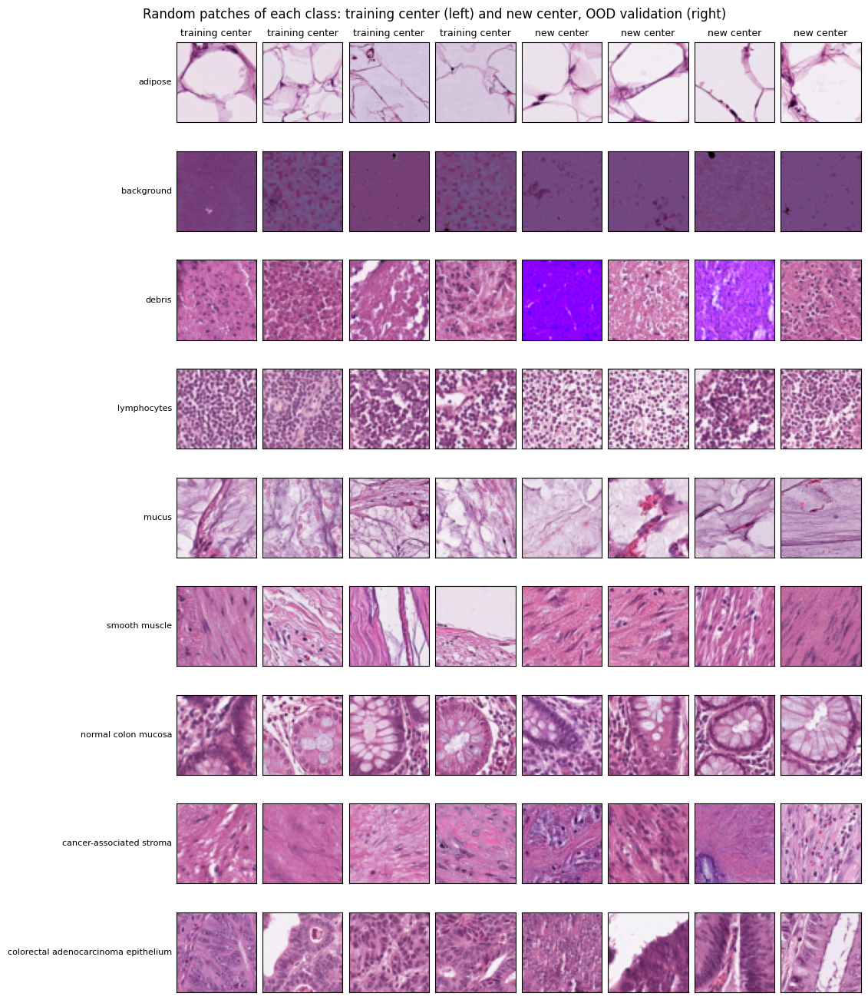

In [7]:
n = 4
rng = np.random.default_rng(seed)

fig, axs = plt.subplots(len(CLASSES), 2 * n, figsize=(2 * n * 1.4, len(CLASSES) * 1.45), constrained_layout=True)
for c, name in enumerate(CLASSES):
    for j, split in enumerate(["train", "ood_val"]):
        X, y = SPLITS[split]
        for k, i in enumerate(rng.choice(np.flatnonzero(y.numpy() == c), size=n, replace=False)):
            ax = axs[c, j * n + k]
            ax.imshow(X[i].permute(1, 2, 0).numpy())
            ax.set_xticks([])
            ax.set_yticks([])
            if c == 0:
                ax.set_title("training center" if split == "train" else "new center", fontsize=9)
    axs[c, 0].set_ylabel(name, fontsize=8, rotation=0, ha="right", va="center")

fig.suptitle("Random patches of each class: training center (left) and new center, OOD validation (right)", fontsize=12)
plt.show()

In [8]:
from scipy.ndimage import sobel, laplace, shift as ndi_shift
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score

EDA_SPLITS = ("train", "id_val", "ood_val")  # deliberately excludes ood_test
CENTER_SPLITS = ("train", "ood_val")
eda_rng = np.random.default_rng(seed)

def sample_per_class(split, max_per_class=300, random_state=seed):
    X, y = SPLITS[split]
    generator = np.random.default_rng(random_state)
    labels = y.numpy()
    idx = np.concatenate([
        generator.choice(ids, size=min(max_per_class, len(ids)), replace=False)
        for c in range(len(CLASSES))
        if (ids := np.flatnonzero(labels == c)).size > 0
    ])
    return X[idx].numpy(), labels[idx]

def to_gray(images):
    # images are NCHW uint8
    rgb_arr = images.astype(np.float32) / 255.0
    return (0.299 * rgb_arr[:, 0] + 0.587 * rgb_arr[:, 1] +
            0.114 * rgb_arr[:, 2])

def image_features(images):
    rgb_arr = images.astype(np.float32) / 255.0
    means = rgb_arr.mean(axis=(2, 3))
    stds = rgb_arr.std(axis=(2, 3))
    gray = to_gray(images)
    gx = sobel(gray, axis=2, mode="reflect") / 8
    gy = sobel(gray, axis=1, mode="reflect") / 8
    grad = np.sqrt(gx * gx + gy * gy).mean(axis=(1, 2))
    lap_var = laplace(gray, mode="reflect").var(axis=(1, 2))
    return np.column_stack((means, stds, grad, lap_var))

FEATURES = ["mean_R", "mean_G", "mean_B", "std_R", "std_G", "std_B",
            "grad_energy", "laplacian_var"]

# Shared features: same sample for RGB, texture, and center classification.
feature_frames = []
for split in EDA_SPLITS:
    patches, labels = sample_per_class(split, max_per_class=300)
    values = image_features(patches)
    frame = pd.DataFrame(values, columns=FEATURES)
    frame["class"] = labels
    frame["class_name"] = [CLASSES[c] for c in labels]
    frame["split"] = split
    feature_frames.append(frame)
eda_df = pd.concat(feature_frames, ignore_index=True)
print(eda_df.groupby(["split", "class_name"], observed=True).size().unstack(0))

split                                 id_val  ood_val  train
class_name                                                  
adipose                                  300      300    300
background                               300      300    300
cancer-associated stroma                 300      210    300
colorectal adenocarcinoma epithelium     300      300    300
debris                                   300      170    300
lymphocytes                              300      300    300
mucus                                    300      300    300
normal colon mucosa                      300      300    300
smooth muscle                            300      296    300


#### Proportion of each class in the three splits

,train,id_val,ood_val
class,,,
adipose,9366,1041,669
background,9509,1057,424
debris,10360,1152,170
lymphocytes,10401,1156,317
mucus,8006,890,518
smooth muscle,12182,1354,296
normal colon mucosa,7886,877,370
cancer-associated stroma,9401,1045,210
colorectal adenocarcinoma epithelium,12885,1432,616


,train,id_val,ood_val
class,,,
adipose,10.41,10.41,18.64
background,10.57,10.57,11.81
debris,11.51,11.52,4.74
lymphocytes,11.56,11.56,8.83
mucus,8.90,8.90,14.43
smooth muscle,13.54,13.53,8.25
normal colon mucosa,8.76,8.77,10.31
cancer-associated stroma,10.45,10.45,5.85
colorectal adenocarcinoma epithelium,14.32,14.31,17.16


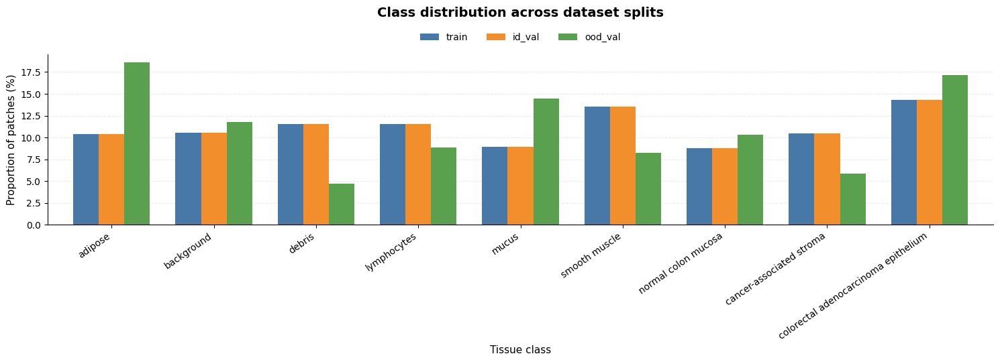

In [9]:
# Class proportions across splits
counts = pd.DataFrame({
    split: np.bincount(SPLITS[split][1].numpy(), minlength=len(CLASSES))
    for split in EDA_SPLITS
}, index=CLASSES)

proportions = counts.div(counts.sum(axis=0), axis=1) * 100

display(counts.rename_axis("class"))
display(proportions.round(2).rename_axis("class"))

# Improved visualization
fig, ax = plt.subplots(figsize=(15, 5.5))

proportions.plot(
    kind="bar",
    ax=ax,
    width=0.75,
    color=["#4878A8", "#F28E2B", "#59A14F"],
    edgecolor="none"
)

ax.set_title(
    "Class distribution across dataset splits",
    fontsize=14,
    fontweight="bold",
    pad=40
)

ax.set_xlabel("Tissue class", fontsize=11)
ax.set_ylabel("Proportion of patches (%)", fontsize=11)

ax.set_xticklabels(
    CLASSES,
    rotation=35,
    ha="right",
    fontsize=10
)

ax.legend(
    title=None,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


#### Distribution of per-patch RGB mean by class and split

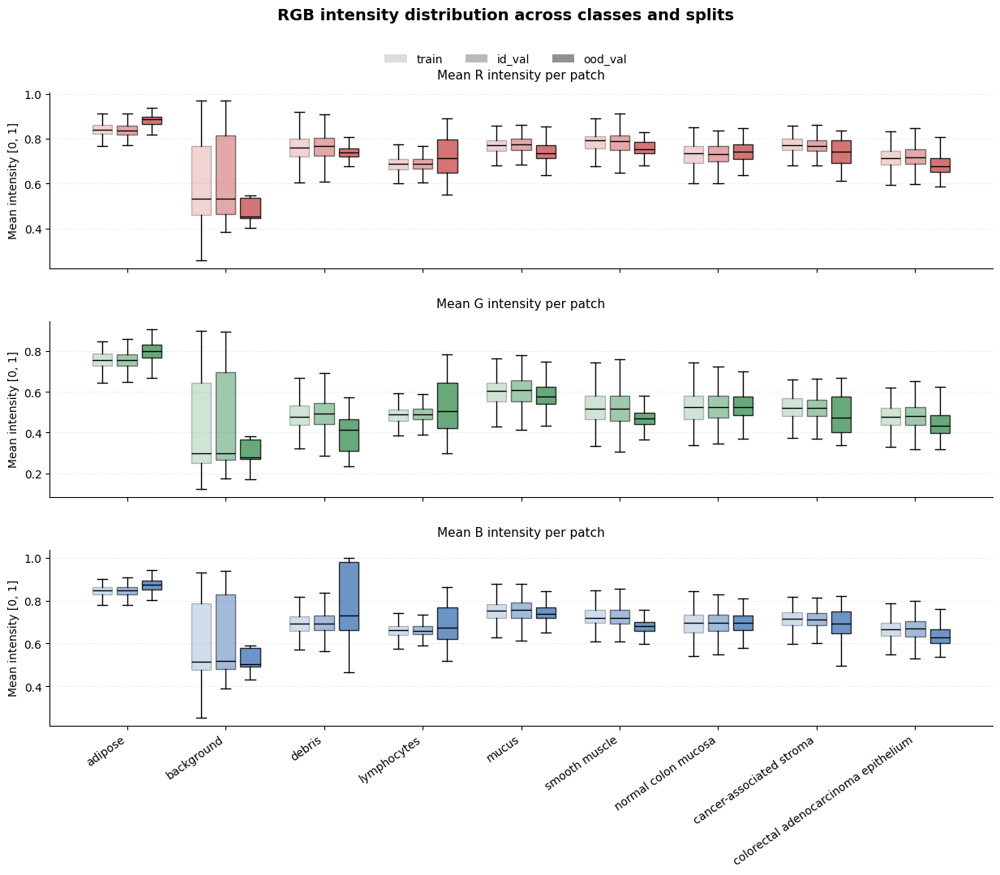

In [10]:
# RGB intensity distribution by class and split
fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 11),
    sharex=True
)

colors = ["#C95353", "#41945A", "#4779B8"]
split_colors = ["#DCE6F2", "#A9C4DF", "#527FAF"]
offsets = [-0.25, 0, 0.25]

for channel, ax, color in zip(
    ("mean_R", "mean_G", "mean_B"), axes, colors
):
    for j, split in enumerate(EDA_SPLITS):
        values = [
            eda_df.loc[
                (eda_df["split"] == split) &
                (eda_df["class"] == c),
                channel
            ].to_numpy()
            for c in range(len(CLASSES))
        ]

        bp = ax.boxplot(
            values,
            positions=np.arange(len(CLASSES)) + offsets[j],
            widths=0.20,
            patch_artist=True,
            showfliers=False,
            manage_ticks=False
        )

        for box in bp["boxes"]:
            box.set_facecolor(color)
            box.set_alpha([0.25, 0.50, 0.80][j])

        for median in bp["medians"]:
            median.set_color("black")

    ax.set_title(
        f"Mean {channel[-1]} intensity per patch",
        fontsize=11,
        pad=12
    )
    ax.set_ylabel("Mean intensity [0, 1]")
    ax.grid(axis="y", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xticks(range(len(CLASSES)))
axes[-1].set_xticklabels(
    CLASSES,
    rotation=35,
    ha="right"
)

from matplotlib.patches import Patch

legend_handles = [
    Patch(
        facecolor="#777777",
        alpha=alpha,
        label=split
    )
    for split, alpha in zip(
        EDA_SPLITS, [0.25, 0.50, 0.80]
    )
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=3,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "RGB intensity distribution across classes and splits",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    top=0.90,
    bottom=0.19,
    hspace=0.30
)

plt.show()

#### Gradient energy and variance by tissue class and center

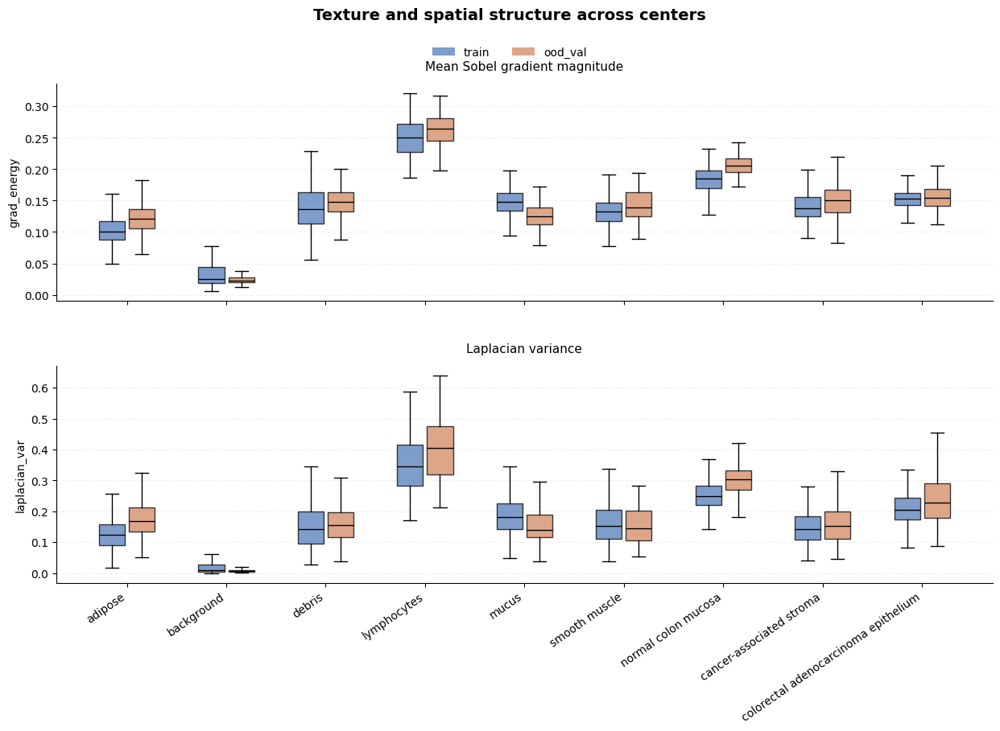

In [11]:
# Texture and spatial structure by class and center
fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 9),
    sharex=True
)

center_colors = {
    "train": "#547DBA",
    "ood_val": "#D38862"
}

features = [
    ("grad_energy", "Mean Sobel gradient magnitude"),
    ("laplacian_var", "Laplacian variance")
]

for ax, (feature, title) in zip(axes, features):

    for j, split in enumerate(CENTER_SPLITS):
        data = [
            eda_df.loc[
                (eda_df["split"] == split) &
                (eda_df["class"] == c),
                feature
            ].to_numpy()
            for c in range(len(CLASSES))
        ]

        bp = ax.boxplot(
            data,
            positions=np.arange(len(CLASSES)) + (j - 0.5) * 0.30,
            widths=0.26,
            patch_artist=True,
            showfliers=False,
            manage_ticks=False
        )

        for box in bp["boxes"]:
            box.set_facecolor(center_colors[split])
            box.set_alpha(0.75)

        for median in bp["medians"]:
            median.set_color("black")

    ax.set_title(title, fontsize=11, pad=12)
    ax.set_ylabel(feature)

    ax.grid(axis="y", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xticks(range(len(CLASSES)))
axes[-1].set_xticklabels(
    CLASSES,
    rotation=35,
    ha="right"
)

from matplotlib.patches import Patch

legend_handles = [
    Patch(
        facecolor=center_colors[split],
        label=split,
        alpha=0.75
    )
    for split in CENTER_SPLITS
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Texture and spatial structure across centers",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    top=0.89,
    bottom=0.20,
    hspace=0.30
)

plt.show()

#### Pixelwise mean brightness and gradient maps, by class and center

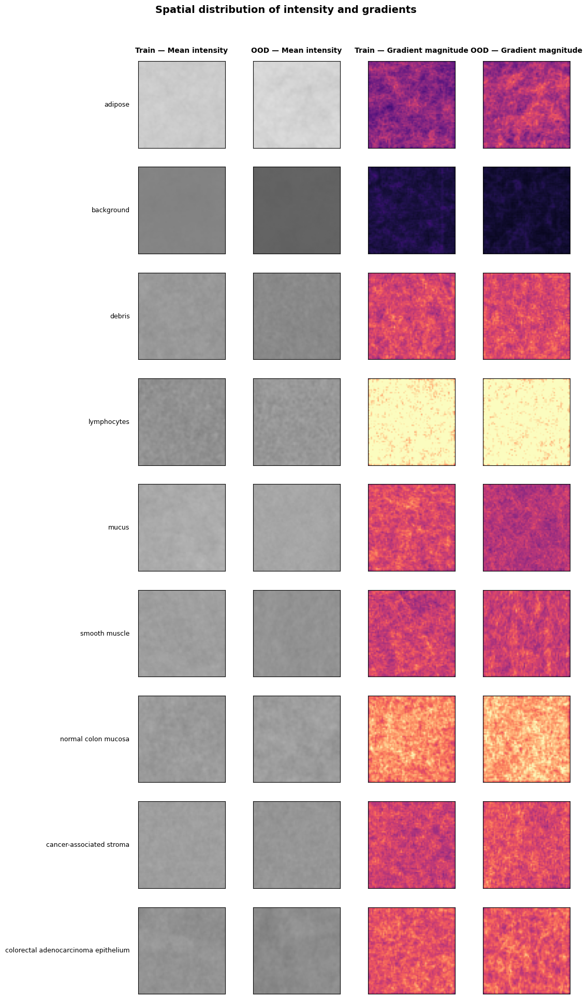

In [12]:
# Spatial distribution of image structures
fig, axes = plt.subplots(
    len(CLASSES), 4,
    figsize=(12, 2.2 * len(CLASSES))
)

titles = [
    "Train — Mean intensity",
    "OOD — Mean intensity",
    "Train — Gradient magnitude",
    "OOD — Gradient magnitude"
]

for j, title in enumerate(titles):
    axes[0, j].set_title(
        title,
        fontsize=10,
        fontweight="bold",
        pad=12
    )

for c, name in enumerate(CLASSES):
    for j, split in enumerate(CENTER_SPLITS):

        X, y = SPLITS[split]

        indices = np.flatnonzero(y.numpy() == c)

        sample = np.random.default_rng(seed + c).choice(
            indices,
            size=min(100, len(indices)),
            replace=False
        )

        gray = to_gray(X[sample].numpy())

        gx = sobel(gray, axis=2, mode="reflect") / 8
        gy = sobel(gray, axis=1, mode="reflect") / 8

        grad = np.sqrt(gx**2 + gy**2)

        axes[c, j].imshow(
            gray.mean(axis=0),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[c, j + 2].imshow(
            grad.mean(axis=0),
            cmap="magma",
            vmin=0,
            vmax=0.25
        )

    axes[c, 0].set_ylabel(
        name,
        rotation=0,
        ha="right",
        va="center",
        fontsize=9,
        labelpad=12
    )

    for ax in axes[c]:
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle(
    "Spatial distribution of intensity and gradients",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    left=0.25,
    right=0.97,
    top=0.94,
    bottom=0.03,
    wspace=0.12,
    hspace=0.22
)

plt.show()


#### Center classification: color vs. texture vs. combined

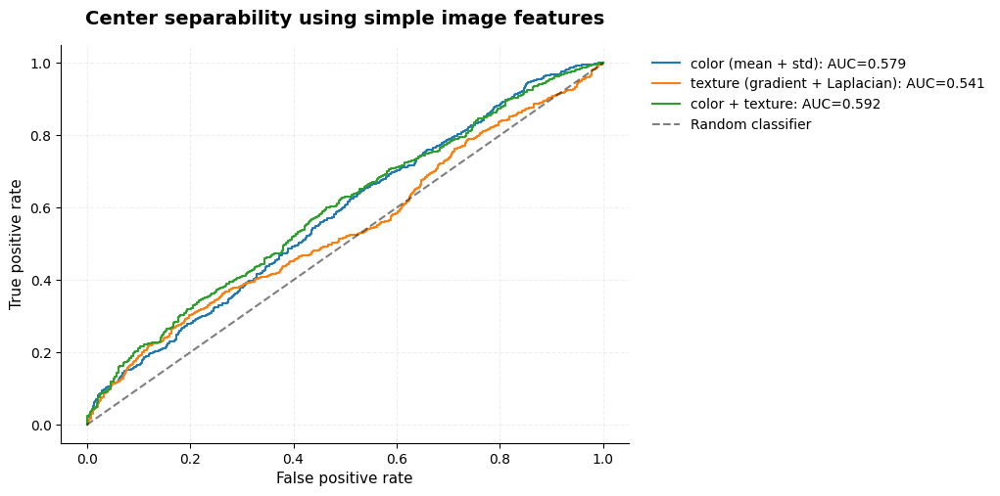

,features,ROC-AUC,balanced_accuracy
0,color (mean + std),0.579,0.541
1,texture (gradient + Laplacian),0.541,0.550
2,color + texture,0.592,0.553


In [13]:
# Center classification: color vs texture vs combined
center_df = eda_df[eda_df["split"].isin(CENTER_SPLITS)].copy()
y_center = (center_df["split"] == "ood_val").astype(int).to_numpy()
strata = center_df["class"].astype(str) + "_" + center_df["split"]

train_idx, test_idx = train_test_split(
    np.arange(len(center_df)), test_size=0.30, random_state=seed,
    stratify=strata
)
groups = {
    "color (mean + std)": FEATURES[:6],
    "texture (gradient + Laplacian)": FEATURES[6:],
    "color + texture": FEATURES,
}
fig, ax = plt.subplots(figsize=(7, 5))
rows = []
for label, cols in groups.items():
    X_feat = center_df[cols].to_numpy()
    classifier = make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=seed)
    )
    classifier.fit(X_feat[train_idx], y_center[train_idx])
    prob = classifier.predict_proba(X_feat[test_idx])[:, 1]
    pred = classifier.predict(X_feat[test_idx])
    auc = roc_auc_score(y_center[test_idx], prob)
    bacc = balanced_accuracy_score(y_center[test_idx], pred)
    fpr, tpr, _ = roc_curve(y_center[test_idx], prob)
    ax.plot(fpr, tpr, label=f"{label}: AUC={auc:.3f}")
    rows.append({"features": label, "ROC-AUC": auc, "balanced_accuracy": bacc})

# Final formatting
ax.plot(
    [0, 1], [0, 1],
    "k--",
    alpha=0.5,
    label="Random classifier"
)

ax.set_xlabel("False positive rate", fontsize=11)
ax.set_ylabel("True positive rate", fontsize=11)

ax.set_title(
    "Center separability using simple image features",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=10
)

ax.grid(
    linestyle="--",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.set_size_inches(10, 5.5)
fig.subplots_adjust(
    left=0.10,
    right=0.68,
    top=0.88,
    bottom=0.14
)

plt.show()

display(pd.DataFrame(rows).round(3))

#### Visualizing geometric and color transformations

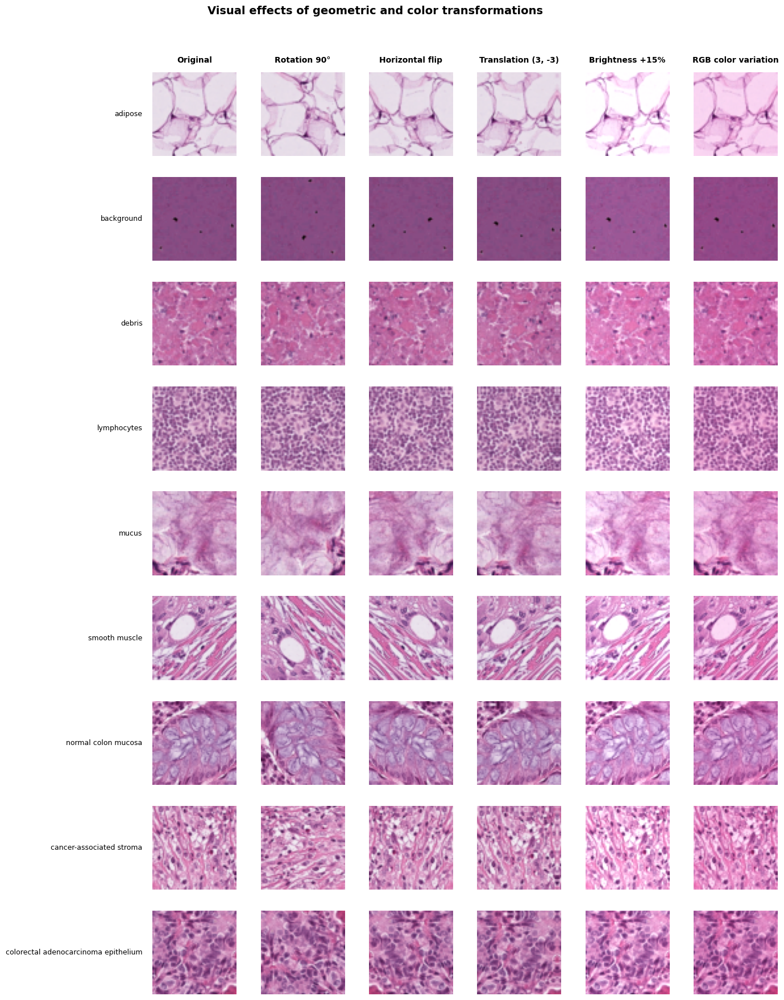

In [14]:

def transformed_examples(image):

    brighter = np.clip(image * 1.15, 0, 1)

    color_jitter = np.clip(
        image * np.array([1.08, 0.96, 1.04]),
        0, 1
    )

    return [
        ("Original", image),
        ("Rotation 90°", np.rot90(image, 1)),
        ("Horizontal flip", np.fliplr(image)),
        (
            "Translation (3, -3)",
            ndi_shift(
                image,
                (3, -3, 0),
                order=1,
                mode="reflect"
            )
        ),
        ("Brightness +15%", brighter),
        ("RGB color variation", color_jitter)
    ]


fig, axes = plt.subplots(
    len(CLASSES), 6,
    figsize=(15, 2.0 * len(CLASSES))
)

for c, name in enumerate(CLASSES):

    X, y = SPLITS["train"]

    pool = np.flatnonzero(y.numpy() == c)

    idx = np.random.default_rng(seed + c).choice(pool)

    img = (
        X[idx]
        .permute(1, 2, 0)
        .numpy()
        .astype(np.float32) / 255.
    )

    for j, (title, output) in enumerate(
        transformed_examples(img)
    ):

        axes[c, j].imshow(output)
        axes[c, j].axis("off")

        if c == 0:
            axes[c, j].set_title(
                title,
                fontsize=10,
                fontweight="bold",
                pad=12
            )

    axes[c, 0].text(
        -0.12, 0.5, name,
        transform=axes[c, 0].transAxes,
        ha="right",
        va="center",
        fontsize=9,
        clip_on=False
    )

fig.suptitle(
    "Visual effects of geometric and color transformations",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    left=0.23,
    right=0.98,
    top=0.93,
    bottom=0.03,
    wspace=0.10,
    hspace=0.25
)

plt.show()


#### HSV color distribution across centers

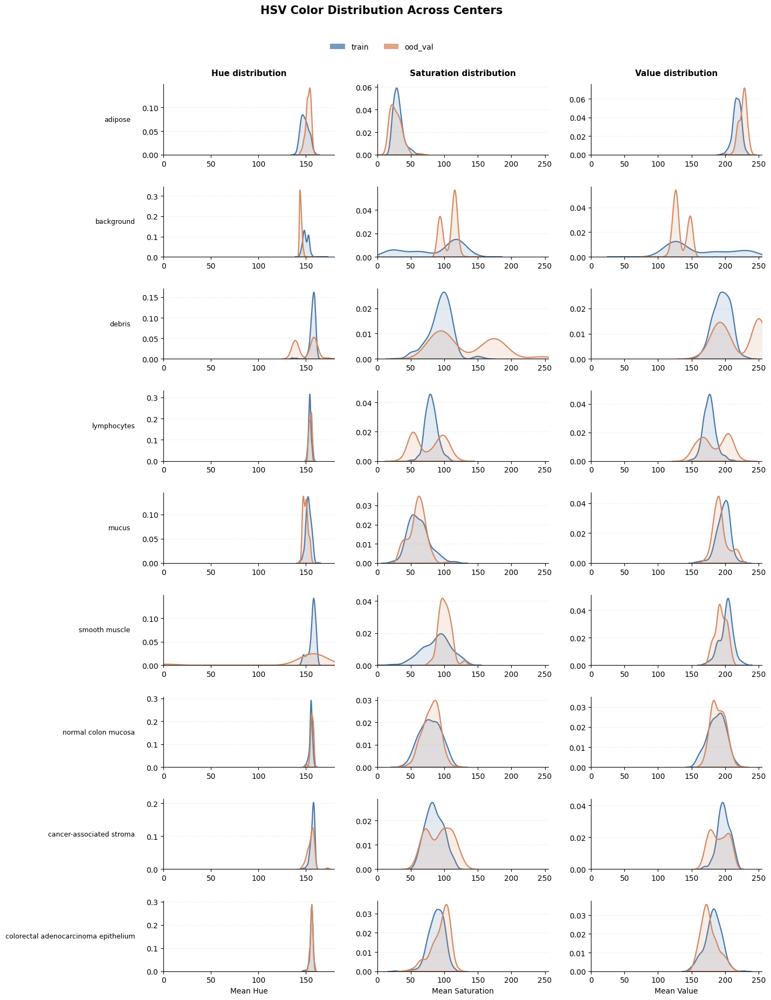

In [15]:
# Compare Hue, Saturation and Value for each tissue class.
import cv2
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Extract HSV features
# --------------------------------------------------

N_PER_CLASS = 300

rng = np.random.default_rng(seed)
records = []

for split in ["train", "ood_val"]:
    X, y = SPLITS[split]
    labels = y.numpy()

    for c, class_name in enumerate(CLASSES):
        indices = np.flatnonzero(labels == c)

        selected = rng.choice(
            indices,
            size=min(N_PER_CLASS, len(indices)),
            replace=False
        )

        for idx in selected:
            rgb = X[idx].permute(1, 2, 0).numpy()
            hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

            hue = hsv[:, :, 0].astype(float)
            sat = hsv[:, :, 1].astype(float)
            val = hsv[:, :, 2].astype(float)

            # Circular mean of hue, weighted by saturation.
            # Hue in OpenCV ranges from 0 to 179.
            theta = hue * (2 * np.pi / 180)
            weights = sat / 255.0

            sin_mean = np.sum(weights * np.sin(theta))
            cos_mean = np.sum(weights * np.cos(theta))

            if np.hypot(sin_mean, cos_mean) > 1e-8:
                hue_mean = (
                    np.arctan2(sin_mean, cos_mean)
                    % (2 * np.pi)
                ) * 180 / (2 * np.pi)
            else:
                hue_mean = np.nan

            records.append({
                "split": split,
                "class": class_name,
                "Hue": hue_mean,
                "Saturation": sat.mean(),
                "Value": val.mean()
            })

hsv_df = pd.DataFrame(records)

# --------------------------------------------------
# 2. Plot distributions by class and center
# --------------------------------------------------

features = ["Hue", "Saturation", "Value"]

colors = {
    "train": "#4878A8",
    "ood_val": "#D38862"
}

fig, axes = plt.subplots(
    len(CLASSES),
    3,
    figsize=(15, 2.1 * len(CLASSES)),
    squeeze=False
)

for i, class_name in enumerate(CLASSES):
    class_data = hsv_df[hsv_df["class"] == class_name]

    for j, feature in enumerate(features):
        ax = axes[i, j]

        for split in ["train", "ood_val"]:
            values = class_data.loc[
                class_data["split"] == split,
                feature
            ].dropna()

            if len(values) > 2 and values.nunique() > 1:
                sns.kdeplot(
                    x=values,
                    ax=ax,
                    color=colors[split],
                    fill=True,
                    alpha=0.15,
                    linewidth=1.6,
                    warn_singular=False
                )

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.2
        )

        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if j == 0:
            ax.set_ylabel(
                class_name,
                fontsize=9,
                rotation=0,
                ha="right",
                va="center",
                labelpad=15
            )
        else:
            ax.set_ylabel("")

        if i == len(CLASSES) - 1:
            ax.set_xlabel(
                f"Mean {feature}",
                fontsize=10
            )
        else:
            ax.set_xlabel("")

        if feature == "Hue":
            ax.set_xlim(0, 180)
        else:
            ax.set_xlim(0, 255)

        if i == 0:
            ax.set_title(
                f"{feature} distribution",
                fontsize=11,
                fontweight="bold",
                pad=12
            )

# --------------------------------------------------
# 3. External legend and figure formatting
# --------------------------------------------------

from matplotlib.patches import Patch

legend_handles = [
    Patch(
        facecolor=colors[split],
        label=split,
        alpha=0.75
    )
    for split in ["train", "ood_val"]
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.967),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "HSV Color Distribution Across Centers",
    fontsize=15,
    fontweight="bold",
    y=0.998
)

fig.subplots_adjust(
    left=0.23,
    right=0.97,
    top=0.92,
    bottom=0.05,
    wspace=0.25,
    hspace=0.45
)

plt.show()


#### Class separability across centers

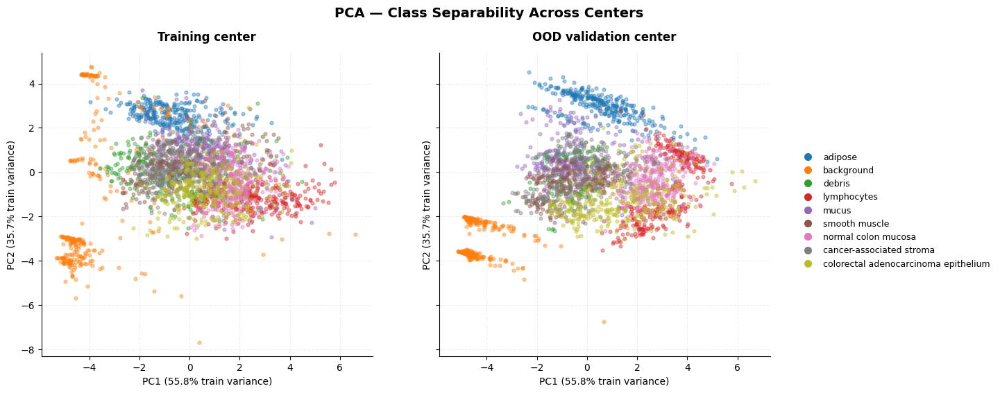

Explained variance (PC1 + PC2): 91.50%


In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from matplotlib.lines import Line2D

# --------------------------------------------------
# 1. Select features and datasets
# --------------------------------------------------

feature_cols = [
    "mean_R", "mean_G", "mean_B",
    "std_R", "std_G", "std_B",
    "grad_energy", "laplacian_var"
]

train_df = eda_df[eda_df["split"] == "train"]
ood_df = eda_df[eda_df["split"] == "ood_val"]

# --------------------------------------------------
# 2. Fit scaler and PCA using train only
# --------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(
    train_df[feature_cols].to_numpy()
)

X_ood = scaler.transform(
    ood_df[feature_cols].to_numpy()
)

pca = PCA(n_components=2, random_state=seed)

Z_train = pca.fit_transform(X_train)
Z_ood = pca.transform(X_ood)

explained = pca.explained_variance_ratio_ * 100

# --------------------------------------------------
# 3. Plot both centers using identical axes
# --------------------------------------------------

cmap = plt.get_cmap("tab10")
class_colors = [cmap(i) for i in range(len(CLASSES))]

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharex=True,
    sharey=True
)

datasets = [
    ("Training center", Z_train, train_df),
    ("OOD validation center", Z_ood, ood_df)
]

for ax, (title, Z, df) in zip(axes, datasets):

    labels = df["class"].to_numpy()

    for c, class_name in enumerate(CLASSES):
        mask = labels == c

        ax.scatter(
            Z[mask, 0],
            Z[mask, 1],
            s=12,
            alpha=0.40,
            color=class_colors[c],
            rasterized=True
        )

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        f"PC1 ({explained[0]:.1f}% train variance)"
    )

    ax.set_ylabel(
        f"PC2 ({explained[1]:.1f}% train variance)"
    )

    ax.grid(
        linestyle="--",
        alpha=0.2
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --------------------------------------------------
# 4. Shared external legend
# --------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=7,
        color=class_colors[c],
        label=class_name
    )
    for c, class_name in enumerate(CLASSES)
]

fig.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(0.79, 0.48),
    frameon=False,
    fontsize=9
)

fig.suptitle(
    "PCA — Class Separability Across Centers",
    fontsize=14,
    fontweight="bold",
    y=0.97
)

fig.subplots_adjust(
    left=0.07,
    right=0.77,
    top=0.86,
    bottom=0.13,
    wspace=0.20
)

plt.show()

print(
    "Explained variance (PC1 + PC2): "
    f"{explained.sum():.2f}%"
)


#### Feature distribution shift across centers

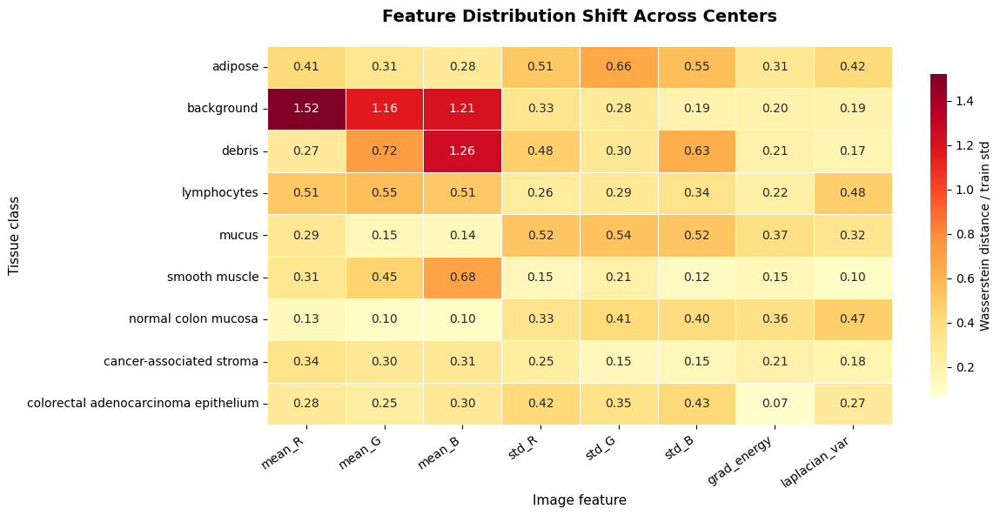

,Mean normalized Wasserstein
mean_B,0.531
mean_R,0.452
mean_G,0.443
std_B,0.370
std_R,0.360
std_G,0.353
laplacian_var,0.289
grad_energy,0.233


In [17]:
from scipy.stats import wasserstein_distance
import seaborn as sns

# --------------------------------------------------
# 1. Define features and calculate train statistics
# --------------------------------------------------

feature_cols = [
    "mean_R", "mean_G", "mean_B",
    "std_R", "std_G", "std_B",
    "grad_energy", "laplacian_var"
]

train_df = eda_df[eda_df["split"] == "train"]
ood_df = eda_df[eda_df["split"] == "ood_val"]

train_std = (
    train_df[feature_cols]
    .std(ddof=0)
    .replace(0, np.nan)
)

# --------------------------------------------------
# 2. Compute normalized Wasserstein distances
# --------------------------------------------------

distances = np.zeros(
    (len(CLASSES), len(feature_cols))
)

for c, class_name in enumerate(CLASSES):

    train_class = train_df[
        train_df["class"] == c
    ]

    ood_class = ood_df[
        ood_df["class"] == c
    ]

    for j, feature in enumerate(feature_cols):

        train_values = (
            train_class[feature]
            .dropna()
            .to_numpy()
        )

        ood_values = (
            ood_class[feature]
            .dropna()
            .to_numpy()
        )

        if (
            len(train_values) > 0
            and len(ood_values) > 0
            and pd.notna(train_std[feature])
        ):
            distance = wasserstein_distance(
                train_values,
                ood_values
            )

            distances[c, j] = (
                distance / train_std[feature]
            )

        else:
            distances[c, j] = np.nan

distance_df = pd.DataFrame(
    distances,
    index=CLASSES,
    columns=feature_cols
)

# --------------------------------------------------
# 3. Plot heatmap
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6.5))

sns.heatmap(
    distance_df,
    ax=ax,
    cmap="YlOrRd",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Wasserstein distance / train std",
        "shrink": 0.85
    }
)

ax.set_title(
    "Feature Distribution Shift Across Centers",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Image feature", fontsize=11)
ax.set_ylabel("Tissue class", fontsize=11)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=35,
    ha="right"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

fig.subplots_adjust(
    left=0.26,
    right=0.95,
    top=0.89,
    bottom=0.22
)

plt.show()

# --------------------------------------------------
# 4. Summary: average shift per feature
# --------------------------------------------------

summary = (
    distance_df
    .mean(axis=0)
    .sort_values(ascending=False)
    .rename("Mean normalized Wasserstein")
    .to_frame()
)

display(summary.round(3))


> **Question.** (1.0 pt)
>
> What are your findings? Describe the task, the balance of the classes, and how the two centers differ. Which
> properties of the patches seem to be stable across centers, and which change from one center to the other?
>
> Based only on this exploration, predict which architecture, MLP or CNN, is more likely to rely on properties that
> change between centers, and why.

The question we asked to guide our EDA was the following: **are the differences between the two clinical centers due solely to image appearance (color, lighting, and contrast) or also to the spatial structure of the tissues (texture, morphology, and cellular organization)**? Here, making this distinction is fundamental to anticipate which approach, MLP or CNN, will be able to generalize better to an unseen clinical setting during training.

Our exploration used only `train`, `id_val`, and `ood_val`, leaving `ood_test` untouched, as previously instructed.

#### 1. Class distribution across dataset splits

- **Findings**: The `train` and `id_val` distributions are nearly identifcal, as expected from their stratified partition. However, `ood_val` exhibits substantial differences. For example, *adipose* increases from approximately 10,4% to 18,5%, *mucus* from 8,9% to 14,5%, and *debris* decreases from 11,5% to 4,7%. *Smooth muscle* and *cancer-associated stroma* are also less frequent in the OOD center.

- **Implications**: This indicates a change in class prevalence between centers, which means that generalization challengers are not limited to image appearance. The alted class distribution may also affect aggregate evaluation metrics. Consequently, comparisons between centers should account for class composition rather than attributing every performance difference to covariate shift.

#### 2. RBG intensity distributions

- **Findings**: The RGB boxplots reveal that color distributions are not perfectly stable between centers. Several classes exhibit noticeable changes in median intensity, spread, or both.

    For instance, *adipose* patches the OOD center generally exhibit higher RGB intensities, whereas *colorectal adenocarcinoma epithelium* tends to have lower channel intensities. The *debris* class shows particularly notable changes in the blue channel, while *background* exhibits substantially different variability.

    Importantly, the direction and magnitude of these changes depend on the tissue class.

- **Implications**: These observations suggest a class-dependent color distribution shift. A model relying heavily on absolute pixel intensities or specific color combinations may learn associations that do not transfer consistently between centers.

#### 3. Texture and local structural characteristics

- **Findings**: Both centers exhibit broadly similar class-dependent patterns. *Lymphocytes* consistently show relatively high gradient magnitude and Laplacian variance, whereas *background* presents extremely low values. This suggests that some local structural characteristics remain informative across centers.

    However, the distributions are not identical. The OOD center exhibits higher gradient and Laplacian values for classes such as *adipose* and *normal colon mucosa*, while *mucus* generally displays lower values.

- **Implications**: Local structural information appears partially preserved across centers, supporting the possibility that models exploiting spatial patterns can learn transferable features.

    Nevertheless, the observed differences indicate that texture is not entirely domain-invariant. Furthermore, Sobel and Laplacian statistics can be affected by contrast, staining, and image acquisition, so they cannot independently establish whether the underlying tissue morphology has changed.

#### 4. Spatial distribution of intensity and gradients

- **Findings**: The averaged intensity maps appear relatively homogeneous, without obvious class-specific structures consistently occupying fixed pixel locations. This is expected because histological structures can appear at different positions within individual patches.

    The gradient maps show more pronounced differences between tissue categories, with *lymphocytes* and *normal colon mucosa* displaying stronger local intensity transitions than background.

    Although some variation between centers is visible, the broad spatial characteristics remain comparable.

- **Implications**: These findings suggest that absolute pixel positions are unlikely to provide a consistently reliable description of tissue identity. Instead, local patterns that can occur throughout a patch may be more useful.

    This observation is relevant to the architectural comparison: CNNs share convolutional filters across spatial positions, whereas standard MLPs operate on flattened inputs and do not explicitly encode spatial translation equivariance.

#### 5. Center separibility using simple image features

- **Findings**: The resulting ROC-AUC scores were:

    | Feature group | ROC-AUC |
    |---|---:|
    | Color (RGB means and standard deviations) | 0.579 |
    | Texture (Sobel gradient and Laplacian variance) | 0.541 |
    | Color + texture | 0.592 |

    All three classifiers perform only modestly above chance, with color features providing more discrimination than the selected texture features. Combining both groups yields a small improvement.

- **Implications**: Although the centers exhibit measurable distributional differences, their identities are not easily distinguishable using these simple global statistics and a linear classifier. This is an important qualification: the existence of a distribution shift does not necessarily imply that center identity is strongly encoded in low-dimensional features.

    More flexible models could detect additional differences, but this cannot be concluded from the present experiment alone.

#### 6. Geometric and color transformations

- **Findings**: Rotations and reflections change the spatial orientation of structures while preserving their visual content. The tissue categories generally remain visually recognizable under these transformations. Brightness and RGB perturbations, on the other hand, modify image appearance without explicitly changing the underlying geometry. Nevertheless, sufficiently strong color transformations may obscure diagnostically relevant information.

- **Implications**: These observations suggest that recognition should ideally be robust to changes in orientation and moderate appearance variations.

    CNNs possess architectural advantages for recognizing recurring local patterns across spatial positions. However, conventional CNNs are not inherently invariant to rotations, reflections, or staining variations, so robustness to these transformations cannot be assumed.

#### 7. HSV color distribution across centers

- **Findings**: The HSV plots reveal different degrees of distribution shift depending on the class and feature.

    Hue distributions often remain concentrated within similar ranges, particularly for *lymphocytes*, *normal colon mucosa*, and *colorectal adenocarcinoma epithelium*. However, some classes show changes in peak location or distribution shape.

    Saturation exhibits more evident changes in several categories, including *background*, *debris*, and *lymphocytes*. Value distributions also reveal noticeable shifts, especially in *adipose*, *background*, and *debris*.

- **Implications**: These results reinforce the conclusion that color-related properties vary between centers, but the changes are neither uniform nor equally strong across classes.

    The differences are consistent with variations in staining or acquisition conditions, although the plots alone cannot establish their physical causes. Moreover, Hue is circular, so distances and apparent overlaps near its scale boundaries must be interpreted carefully.

#### 8. PCA: class separability across centers

- **Findings**: The first two principal components explain approximately 91.5% of the feature variance in the training data (55.8% and 35.7%, respectively).

    The projections reveal substantial overlap among several tissue classes in both centers, suggesting that the selected low-dimensional features are insufficient for consistently distinguishing all nine categories.

    Nevertheless, certain classes, particularly *background* and *adipose*, occupy more distinctive regions of the feature space.

    Importantly, the OOD projection exhibits changes in cluster locations, dispersion, and overall organization. The *background* class shows especially noticeable differences between centers, while other classes retain partially overlapping regions.

- **Implications**: These observations indicate that the relationships among simple color and texture features are not completely preserved across centers. At the same time, the persistence of some class-specific organization suggests that transferable information remains available. The PCA results describe the selected handcrafted features rather than the internal representations that an MLP or CNN would necessarily learn.

#### 9. Quantifying feature distribution shift

- **Findings**: The heatmap confirms that the magnitude of the distribution shift depends strongly on both the tissue class and the feature considered.

    *Background* exhibits particularly large shifts in mean RGB intensity, with normalized distances of approximately 1.52, 1.16, and 1.21 for the red, green, and blue channels, respectively.

    *Debris* also presents a substantial shift in mean blue intensity (1.26), while *adipose* exhibits moderate differences in RGB variability.

    In contrast, several texture-related distances are relatively small. For example, gradient energy presents distances of approximately 0.07 for *colorectal adenocarcinoma epithelium* and 0.15 for *smooth muscle*.

    However, texture-related shifts are not negligible for every class: Laplacian variance reaches approximately 0.48 for *lymphocytes* and 0.47 for *normal colon mucosa*.

- **Implications**: The results provide quantitative support for the observation that color-related properties can change considerably between centers, while some local structural statistics exhibit greater relative stability.

    Nevertheless, neither color nor texture is universally stable. The degree of shift is class-dependent, suggesting that a single global characterization of the domain difference would be insufficient.

### Overall findings and architectural hypothesis

Our EDA reveals that the PathMNIST classification task involves both changes in class prevalence and changes in the visual distributions of histopathology patches across clinical centers.

The most prominent findings are:

1. **Class composition changes substantially**: the OOD center contains different proportions of the nine tissue categories.

2. **Color characteristics are not fully stable**: RGB and HSV statistics reveal class-dependent shifts in intensity, saturation, and brightness.

3. **Local structural information is partially preserved**: gradient and Laplacian statistics retain broadly similar class-dependent patterns, although measurable shifts remain.

4. **Simple features are only weakly predictive of center identity**: the best diagnostic classifier achieves an ROC-AUC of approximately 0.592.

5. **Feature-space organization changes between centers**: PCA and Wasserstein distances confirm that the shift affects different classes and features unequally.

### Which architecture is more likely to rely on changing properties?

Based on this exploration, our initial hyphothesis is that an MLP is more likely than a CNN to rely on properties that are unstable across centers.

A standard MLP receives flattened images and learns independent connections associated with individual pixel positions. Without explicit spatial inductive biases, it has greater freedom to exploit position-specific color combinations, intensity patterns, and other correlations that may be particular to the training distribution.

This is especially relevant because our EDA identifies changes in RGB and HSV statistics, while the spatial maps and transformation examples suggest that tissue structures do not occupy fixed locations within patches.

In contrast, CNNs exploit local connectivity and weight sharing, allowing the same filters to detect similar structures at different spatial positions. This inductive bias may encourage greater reliance on recurring morphological patterns rather than absolute pixel locations.

The relatively consistent class-dependent gradient and texture characteristics provide some exploratory support for this hypothesis.

However, **CNNs are not inherently invariant to color or texture shifts**. Convolutional filters can also learn staining-dependent patterns, and the EDA demonstrates that some local structural statistics change between centers. Consequently, a CNN could still suffer substantial OOD degradation.

Furthermore, the weak separability of centers using simple global features suggests that the domain shift should not automatically be characterized as a strong or easily exploitable shortcut.

### Final prediction

We therefore predict that the **CNN will generalize better than the MLP to the OOD center**, primarily because its spatial inductive bias is better suited to recognizing local histological structures independently of their absolute positions. This expectation is supported by the partial stability of structural characteristics and the observed variability in color-related features.

Nevertheless, the EDA cannot establish which features either architecture will actually learn. The prediction remains a hypothesis to be tested in the subsequent experiments by comparing in-distribution and out-of-distribution performance.

The central question is whether the CNN's advantages in spatial feature extraction outweigh its potential sensitivity to the color and texture changes observed between centers.

---

## Training utilities

All the experiments train and evaluate models with the same four functions, which you will implement in the next
cell. The hands-on of Lecture 18 contains a training loop that you can start from.

> **Implementation.** (1.0 pt)
>
> Implement the four functions below, keeping their names, arguments and return values, since the rest of the notebook
> uses them:
>
> - `make_loader(split, batch_size, shuffle, shuffle_seed)` returns a `DataLoader` over the patches and labels of
>   `SPLITS[split]`. When `shuffle=True`, the order must be **reproducible**: shuffle with a `torch.Generator` seeded
>   with `shuffle_seed`.
> - `predict(model, loader, preprocess, input_fn=None)` returns the predicted classes and the true labels of a whole
>   loader, as two NumPy arrays. Each batch goes through `preprocess` and then, if it is given, through `input_fn`
>   (used in Experiment 2). The model must be in evaluation mode, and no gradients are needed.
> - `evaluate(model, loader, preprocess, input_fn=None)` returns `{"acc": ..., "bal_acc": ...}`, the accuracy and the
>   balanced accuracy of the predictions of `predict`.
> - `fit(model, train_loader, val_loader, optimizer, n_epochs, preprocess, augment=None, verbose=True)` trains the
>   model with `nn.CrossEntropyLoss` (all models output **9 logits** per patch, and the loss applies the softmax).
>   Each training batch goes through `preprocess(x, augment)`. After every epoch, `fit` evaluates the model on
>   `val_loader` and keeps a copy of the weights of the epoch with the best **ID validation balanced accuracy** (early
>   stopping). At the end it restores those weights, so the model used afterwards is the one of the best epoch. It
>   returns a dictionary `history` with:
>   - `"train_loss"`, `"train_acc"`, `"val_acc"`, `"val_bal_acc"`: lists with one value per epoch;
>   - `"best_epoch"`: the epoch whose weights were kept, counting from 1;
>   - `"train_time"`: the total training time, in seconds.
>
>   With `verbose=True`, it prints the metrics of each epoch.
>
> Model selection inside `fit` must use only the ID validation split. Run the sanity check below before starting the
> experiments.

The cell after your implementation is already complete:
- `report` evaluates a trained model on the ID and the OOD validation splits and stores the results in `RESULTS`,
  which you will use in the Summary table;
- `plot_histories` plots the histories returned by `fit`.

In [18]:
def make_loader(split: str, batch_size: int = 512, shuffle: bool = False,
                shuffle_seed: int = seed) -> DataLoader:
    # Create a DataLoader for the requested dataset split.
    X, y = SPLITS[split]

    generator = (
        torch.Generator().manual_seed(shuffle_seed)
        if shuffle else None
    )

    return DataLoader(
        TensorDataset(X, y),
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        pin_memory=(DEVICE == "cuda")
    )


def predict(model: nn.Module, loader: DataLoader,
            preprocess: Preprocess, input_fn=None) -> tuple[np.ndarray, np.ndarray]:
    # Predict all batches without computing gradients.
    model.eval()

    predictions = []
    labels = []

    with torch.no_grad():
        for x, y in loader:
            x = preprocess(x)

            if input_fn is not None:
                x = input_fn(x)

            logits = model(x)
            pred = logits.argmax(dim=1)

            predictions.append(pred.cpu().numpy())
            labels.append(y.cpu().numpy())

    return np.concatenate(predictions), np.concatenate(labels)


def evaluate(model: nn.Module, loader: DataLoader,
             preprocess: Preprocess, input_fn=None) -> dict[str, float]:
    # Compute accuracy and balanced accuracy.
    preds, labels = predict(model, loader, preprocess, input_fn)

    acc = (preds == labels).mean()
    bal_acc = balanced_accuracy_score(labels, preds)

    return {
        "acc": float(acc),
        "bal_acc": float(bal_acc)
    }


def fit(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
        optimizer: optim.Optimizer, n_epochs: int, preprocess: Preprocess,
        augment=None, verbose: bool = True) -> dict:
    # Train the model and retain the epoch with the highest
    # ID validation balanced accuracy.

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_bal_acc": [],
        "best_epoch": None,
        "train_time": None
    }

    loss_fn = nn.CrossEntropyLoss()

    best_bal_acc = -1.0
    best_weights = None

    start_time = time.perf_counter()

    for epoch in range(1, n_epochs + 1):

        # ------------------------------------------
        # Training
        # ------------------------------------------
        model.train()

        total_loss = 0.0
        correct = 0
        n = 0

        for x, y in train_loader:
            x = preprocess(x, augment)
            y = y.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()

            logits = model(x)
            loss = loss_fn(logits, y)

            loss.backward()
            optimizer.step()

            batch_size = y.size(0)

            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += batch_size

        train_loss = total_loss / n
        train_acc = correct / n

        # ------------------------------------------
        # ID validation (no augmentation)
        # ------------------------------------------
        val_metrics = evaluate(model, val_loader, preprocess)

        val_acc = val_metrics["acc"]
        val_bal_acc = val_metrics["bal_acc"]

        # Store metrics for the current epoch.
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_bal_acc"].append(val_bal_acc)

        # ------------------------------------------
        # Keep the best model checkpoint
        # ------------------------------------------
        if val_bal_acc > best_bal_acc:
            best_bal_acc = val_bal_acc
            best_weights = copy.deepcopy(model.state_dict())
            history["best_epoch"] = epoch

        if verbose:
            print(
                f"Epoch {epoch:2d}/{n_epochs} | "
                f"train loss {train_loss:.4f} | "
                f"train acc {train_acc:.4f} | "
                f"val acc {val_acc:.4f} | "
                f"val bal acc {val_bal_acc:.4f}"
            )

    # Restore weights from the best validation epoch.
    model.load_state_dict(best_weights)

    history["train_time"] = time.perf_counter() - start_time

    if verbose:
        print(
            f"\nBest epoch: {history['best_epoch']} | "
            f"ID val balanced accuracy: {best_bal_acc:.4f} | "
            f"Training time: {history['train_time']:.2f}s"
        )

    return history

In [19]:
RESULTS: dict[str, dict] = {}   # one row per trained model, filled by report()
MODELS: dict[str, tuple] = {}   # name -> (model, Preprocess used to evaluate it)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def report(name: str, model: nn.Module, preprocess: Preprocess, history: dict | None = None) -> dict:
    # ID and OOD validation metrics of a trained model, stored in RESULTS.
    id_m = evaluate(model, make_loader("id_val"), preprocess)
    ood_m = evaluate(model, make_loader("ood_val"), preprocess)
    RESULTS[name] = {
        "params": count_params(model),
        "train_time_s": round(history["train_time"]) if history else None,
        "id_acc": id_m["acc"], "id_bal_acc": id_m["bal_acc"],
        "ood_acc": ood_m["acc"], "ood_bal_acc": ood_m["bal_acc"],
        "gap_bal_acc": id_m["bal_acc"] - ood_m["bal_acc"],
    }
    MODELS[name] = (model, preprocess)
    r = RESULTS[name]
    print(f"{name}: ID bal. acc {r['id_bal_acc']:.3f} | OOD bal. acc {r['ood_bal_acc']:.3f} | gap {r['gap_bal_acc']:+.3f} "
          f"| ID acc {r['id_acc']:.3f} | OOD acc {r['ood_acc']:.3f}")
    return r


def plot_histories(histories: dict[str, dict], title: str = "") -> None:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = range(1, len(h["train_loss"]) + 1)
        axs[0].plot(epochs, h["train_loss"], color=color, label=name)
        axs[1].plot(epochs, h["train_acc"], "--", color=color, alpha=0.7)
        axs[1].plot(epochs, h["val_acc"], color=color, label=name)
        axs[2].plot(epochs, h["val_bal_acc"], color=color, label=name)
        best = h["best_epoch"]
        axs[2].scatter(best, h["val_bal_acc"][best - 1], marker="*", s=150, color=color, edgecolor="black", zorder=5)
    titles = ["training loss", "accuracy (dashed = train, solid = ID val)", "ID val balanced accuracy (star = kept epoch)"]
    for ax, t in zip(axs, titles):
        ax.set_title(t)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

In [20]:
# Restore the original PyTorch tensors from SPLITS

X_train, y_train = SPLITS["train"]
X_id_val, y_id_val = SPLITS["id_val"]

print("X_train:", type(X_train), X_train.shape)
print("y_train:", type(y_train), y_train.shape)


X_train: <class 'torch.Tensor'> torch.Size([89996, 3, 64, 64])
y_train: <class 'torch.Tensor'> torch.Size([89996])


In [21]:
# Restore the original variables used by the assignment

X_train, y_train = SPLITS["train"]
X_id_val, y_id_val = SPLITS["id_val"]

rgb = Preprocess()

# Verify that everything is correct
print("X_train:", type(X_train))
print("rgb:", type(rgb))
print("rgb is callable:", callable(rgb))


X_train: <class 'torch.Tensor'>
rgb: <class '__main__.Preprocess'>
rgb is callable: True


In [22]:
# Sanity check of your implementation, with a tiny model and 2,000 training patches (a few seconds).
torch.manual_seed(seed)
check_model = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(3 * 64 * 64, len(CLASSES))).to(DEVICE)
check_train = DataLoader(TensorDataset(X_train[:2_000], y_train[:2_000]), batch_size=128, shuffle=True)
check_val = DataLoader(TensorDataset(X_id_val[:1_000], y_id_val[:1_000]), batch_size=512)
check_history = fit(check_model, check_train, check_val, optim.Adam(check_model.parameters(), lr=1e-3), 3, rgb,
                    verbose=False)

preds, labels = predict(check_model, check_val, rgb)
assert preds.shape == labels.shape == (1_000,), "predict must return one prediction and one label per patch"
assert np.array_equal(preds, predict(check_model, check_val, rgb)[0]), "predict must put the model in evaluation mode"
for key in ["train_loss", "train_acc", "val_acc", "val_bal_acc"]:
    assert len(check_history[key]) == 3, f'history["{key}"] must have one value per epoch'
assert check_history["train_time"] is not None, 'history["train_time"] is missing'
best = check_history["best_epoch"]
assert best in (1, 2, 3) and check_history["val_bal_acc"][best - 1] == max(check_history["val_bal_acc"]), \
    "best_epoch must be the epoch with the best ID validation balanced accuracy, counting from 1"
assert abs(evaluate(check_model, check_val, rgb)["bal_acc"] - check_history["val_bal_acc"][best - 1]) < 1e-6, \
    "fit must restore the weights of the best epoch"
first_batch = lambda: next(iter(make_loader("train", batch_size=8, shuffle=True)))[1]
assert torch.equal(first_batch(), first_batch()), "the shuffled order must be reproducible (use shuffle_seed)"
print("All checks passed.")

All checks passed.


---

## Experiment 1: Is the Convolutional Structure Necessary?

A CNN builds three assumptions into the network:
- **locality**: each unit of a convolutional layer looks only at a small neighborhood of the previous layer;
- **weight sharing**: the same filter is applied at every position, so a pattern is detected wherever it appears;
- **hierarchy**: deeper layers combine the patterns of earlier ones, over larger and larger regions.

An MLP applied to the flattened pixels has none of them: each of the 64×64×3 = 12,288 inputs has its own weight in
every unit of the first layer, and any spatial relationship must be learned from the data. In Lecture 18, the same
MLP that worked on Fashion-MNIST (centered, aligned objects) failed on CIFAR-10 (objects anywhere in the image),
while a CNN with 5 times fewer parameters did much better. Are tissue patches closer to the first case or to the
second?

This comparison also illustrates that **the number of parameters does not determine generalization**: the first
layer of the MLP alone has about 65 times more parameters than the whole SmallCNN.

> **Question:**
>
> Does the spatial inductive bias of a CNN improve in-distribution performance *and* generalization to a new
> clinical center, compared with an MLP with many more parameters trained under the same conditions?

> **Hypothesis:**
>
> A tissue class is defined by local patterns (the shape, size and density of nuclei and fibers, the arrangement of
> glands and cells), which can appear at any position of the patch and are the same in every center. A SmallCNN, which
> detects local patterns anywhere with shared filters, will therefore reach a **higher balanced accuracy than the MLP
> on both the ID and the OOD validation splits**, and a **smaller ID–OOD gap**, despite having more than 60 times fewer
> parameters.
> The hypothesis is contradicted if the MLP matches or beats the CNN on the OOD validation balanced accuracy, or if the
> gap of the CNN is not smaller than the gap of the MLP.

> **Baseline:**
>
> A classifier that always predicts the same class has balanced accuracy 1/9 ≈ 0.11.

In [23]:
class MLP(nn.Module):
    # Fully connected network on the flattened patch:
    # no spatial inductive bias.

    def __init__(
        self,
        input_size: int,
        hidden_sizes: list[int],
        n_classes: int = 9,
        dropout: float = 0.0
    ) -> None:
        super().__init__()

        layers = [nn.Flatten()]

        in_features = input_size

        for hidden_size in hidden_sizes:
            layers.extend([
                nn.Linear(in_features, hidden_size),
                nn.ReLU(),
                nn.Dropout(p=dropout)
            ])

            in_features = hidden_size

        layers.append(nn.Linear(in_features, n_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


class SmallCNN(nn.Module):
    # Small convolutional network:
    # locality, weight sharing and hierarchy.

    def __init__(
        self,
        channels: tuple[int, ...] = (32, 64, 128),
        n_classes: int = 9
    ) -> None:
        super().__init__()

        layers = []

        in_channels = 3

        for out_channels in channels:
            layers.extend([
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=3,
                    padding=1
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2)
            ])

            in_channels = out_channels

        layers.extend([
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels[-1], n_classes)
        ])

        self.network = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


In [24]:
mlp = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256])
cnn = SmallCNN()

print(f"MLP parameters      : {count_params(mlp):>12,}")
print(f"SmallCNN parameters : {count_params(cnn):>12,}")
print()
print("Both models receive the same standardized 64x64x3 patches and are trained with the same loop.")

MLP parameters      :    6,425,609
SmallCNN parameters :       94,857

Both models receive the same standardized 64x64x3 patches and are trained with the same loop.


In [25]:
train_loader = make_loader("train", batch_size=128, shuffle=True)
id_val_loader = make_loader("id_val")

# Equal hyperparameter search budget: 3 configurations per model.
# Model selection uses ID validation balanced accuracy only.

n_epochs = 15

mlp_configs = [
    {"learning_rate": 1e-3, "dropout": 0.3},
    {"learning_rate": 3e-4, "dropout": 0.5},
    {"learning_rate": 1e-4, "dropout": 0.0}
]

cnn_configs = [
    {"learning_rate": 1e-3},
    {"learning_rate": 3e-4},
    {"learning_rate": 1e-4}
]

# Keep the original configuration variables available.
learning_rate = 1e-3
dropout = 0.3


In [26]:
# Experiment 1 — MLP hyperparameter tuning

mlp_trials = []
best_mlp_score = -1.0

for i, config in enumerate(mlp_configs, start=1):

    print(f"\nMLP trial {i}/{len(mlp_configs)}: {config}")

    torch.manual_seed(seed)

    candidate = MLP(
        input_size=3 * 64 * 64,
        hidden_sizes=[512, 256],
        dropout=config["dropout"]
    ).to(DEVICE)

    mlp_optimizer = optim.Adam(
        candidate.parameters(),
        lr=config["learning_rate"]
    )

    # Same reproducible data order for every trial
    trial_loader = make_loader(
        "train",
        batch_size=128,
        shuffle=True,
        shuffle_seed=seed
    )

    history = fit(
        candidate,
        trial_loader,
        id_val_loader,
        mlp_optimizer,
        n_epochs,
        rgb,
        verbose=False
    )

    score = max(history["val_bal_acc"])

    mlp_trials.append({
        **config,
        "best_epoch": history["best_epoch"],
        "id_bal_acc": score,
        "train_time_s": history["train_time"]
    })

    print(
        f"ID balanced accuracy: {score:.4f} | "
        f"Best epoch: {history['best_epoch']}"
    )

    if score > best_mlp_score:
        best_mlp_score = score
        best_mlp_config = config.copy()
        mlp = candidate
        mlp_history = history

print("\nBest MLP configuration:", best_mlp_config)

display(
    pd.DataFrame(mlp_trials)
    .sort_values("id_bal_acc", ascending=False)
    .round(4)
)

# OOD evaluation only after ID-based model selection
report("MLP (Exp. 1)", mlp, rgb, mlp_history)


MLP trial 1/3: {'learning_rate': 0.001, 'dropout': 0.3}
ID balanced accuracy: 0.6625 | Best epoch: 15

MLP trial 2/3: {'learning_rate': 0.0003, 'dropout': 0.5}
ID balanced accuracy: 0.6812 | Best epoch: 15

MLP trial 3/3: {'learning_rate': 0.0001, 'dropout': 0.0}
ID balanced accuracy: 0.6667 | Best epoch: 6

Best MLP configuration: {'learning_rate': 0.0003, 'dropout': 0.5}


,learning_rate,dropout,best_epoch,id_bal_acc,train_time_s
1,0.0003,0.5,15,0.6812,55.2415
2,0.0001,0.0,6,0.6667,54.2642
0,0.0010,0.3,15,0.6625,56.0320


MLP (Exp. 1): ID bal. acc 0.681 | OOD bal. acc 0.545 | gap +0.137 | ID acc 0.681 | OOD acc 0.627


{'params': 6425609,
 'train_time_s': 55,
 'id_acc': 0.681327469012395,
 'id_bal_acc': 0.6812397645777153,
 'ood_acc': 0.6270194986072424,
 'ood_bal_acc': 0.5445624941318918,
 'gap_bal_acc': 0.13667727044582345}

In [27]:
# Experiment 1 — SmallCNN hyperparameter tuning

cnn_trials = []
best_cnn_score = -1.0

for i, config in enumerate(cnn_configs, start=1):

    print(f"\nCNN trial {i}/{len(cnn_configs)}: {config}")

    torch.manual_seed(seed)

    candidate = SmallCNN().to(DEVICE)

    cnn_optimizer = optim.Adam(
        candidate.parameters(),
        lr=config["learning_rate"]
    )

    # Same reproducible data order for every trial
    trial_loader = make_loader(
        "train",
        batch_size=128,
        shuffle=True,
        shuffle_seed=seed
    )

    history = fit(
        candidate,
        trial_loader,
        id_val_loader,
        cnn_optimizer,
        n_epochs,
        rgb,
        verbose=False
    )

    score = max(history["val_bal_acc"])

    cnn_trials.append({
        **config,
        "best_epoch": history["best_epoch"],
        "id_bal_acc": score,
        "train_time_s": history["train_time"]
    })

    print(
        f"ID balanced accuracy: {score:.4f} | "
        f"Best epoch: {history['best_epoch']}"
    )

    if score > best_cnn_score:
        best_cnn_score = score
        best_cnn_config = config.copy()
        cnn = candidate
        cnn_history = history

print("\nBest CNN configuration:", best_cnn_config)

display(
    pd.DataFrame(cnn_trials)
    .sort_values("id_bal_acc", ascending=False)
    .round(4)
)

# OOD evaluation only after ID-based model selection
report("SmallCNN (Exp. 1)", cnn, rgb, cnn_history)


CNN trial 1/3: {'learning_rate': 0.001}
ID balanced accuracy: 0.9814 | Best epoch: 9

CNN trial 2/3: {'learning_rate': 0.0003}
ID balanced accuracy: 0.9745 | Best epoch: 15

CNN trial 3/3: {'learning_rate': 0.0001}
ID balanced accuracy: 0.9657 | Best epoch: 14

Best CNN configuration: {'learning_rate': 0.001}


,learning_rate,best_epoch,id_bal_acc,train_time_s
0,0.0010,9,0.9814,317.1989
1,0.0003,15,0.9745,313.6987
2,0.0001,14,0.9657,313.4154


SmallCNN (Exp. 1): ID bal. acc 0.981 | OOD bal. acc 0.834 | gap +0.147 | ID acc 0.982 | OOD acc 0.858


{'params': 94857,
 'train_time_s': 317,
 'id_acc': 0.9820071971211516,
 'id_bal_acc': 0.9814151777062468,
 'ood_acc': 0.8582172701949861,
 'ood_bal_acc': 0.8341431064415187,
 'gap_bal_acc': 0.14727207126472808}

In [28]:
# Plot the training histories of both models (plot_histories) and analyze the results. Examples of figures:
# - the recall of each class on the ID and on the OOD validation splits, and the confusion matrices
#   (sklearn.metrics.confusion_matrix with the outputs of predict());
# - the first-layer weights of the MLP, reshaped to 64x64x3 images, and the first-layer filters of the CNN;
# - a 2D projection (PCA or t-SNE) of the last hidden representation of each model, colored by class and by center
#   (id_val vs. ood_val).

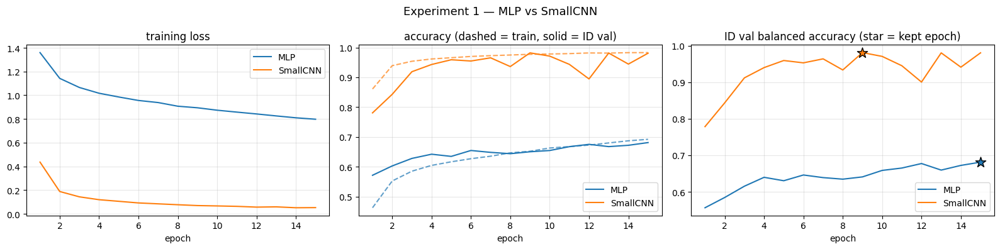

,params,train_time_s,id_acc,id_bal_acc,ood_acc,ood_bal_acc,gap_bal_acc
MLP (Exp. 1),6425609.0,55.0,0.6813,0.6812,0.6270,0.5446,0.1367
SmallCNN (Exp. 1),94857.0,317.0,0.9820,0.9814,0.8582,0.8341,0.1473


,model,learning_rate,dropout,best_epoch,id_bal_acc
0,MLP,0.0003,0.5,15,0.6812
1,SmallCNN,0.0010,NaN,9,0.9814


In [29]:
# Experiment 1 — Training histories

plot_histories(
    {
        "MLP": mlp_history,
        "SmallCNN": cnn_history
    },
    title="Experiment 1 — MLP vs SmallCNN"
)

# Overall model comparison
model_names = ["MLP (Exp. 1)", "SmallCNN (Exp. 1)"]

exp1_results = pd.DataFrame({
    name: RESULTS[name]
    for name in model_names
}).T

display(exp1_results.round(4))

# Selected configurations
selected_configs = pd.DataFrame([
    {
        "model": "MLP",
        "learning_rate": best_mlp_config["learning_rate"],
        "dropout": best_mlp_config["dropout"],
        "best_epoch": mlp_history["best_epoch"],
        "id_bal_acc": best_mlp_score
    },
    {
        "model": "SmallCNN",
        "learning_rate": best_cnn_config["learning_rate"],
        "dropout": np.nan,
        "best_epoch": cnn_history["best_epoch"],
        "id_bal_acc": best_cnn_score
    }
])

display(selected_configs.round(4))


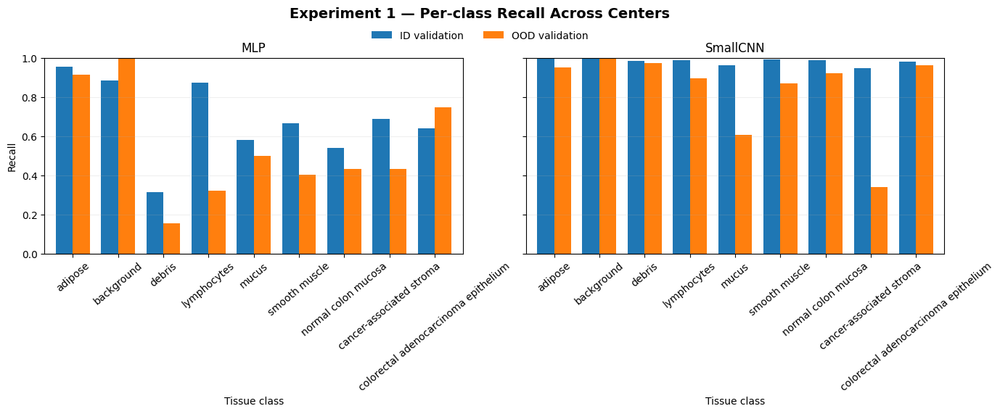

In [30]:
# Experiment 1 — Per-class recall

from sklearn.metrics import recall_score

models = {
    "MLP": mlp,
    "SmallCNN": cnn
}

recall_records = []

for model_name, model in models.items():
    for split in ["id_val", "ood_val"]:

        loader = make_loader(split)
        preds, labels = predict(model, loader, rgb)

        recalls = recall_score(
            labels,
            preds,
            labels=np.arange(len(CLASSES)),
            average=None,
            zero_division=0
        )

        for c, value in enumerate(recalls):
            recall_records.append({
                "model": model_name,
                "split": split,
                "class": CLASSES[c],
                "recall": value
            })

recall_df = pd.DataFrame(recall_records)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, model_name in zip(axes, models):

    data = recall_df[recall_df["model"] == model_name]

    pivot = data.pivot(
        index="class",
        columns="split",
        values="recall"
    ).reindex(CLASSES)

    pivot[["id_val", "ood_val"]].plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title(model_name)
    ax.set_xlabel("Tissue class")
    ax.set_ylabel("Recall")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=40)
    ax.grid(axis="y", alpha=0.2)
    ax.get_legend().remove()

fig.suptitle(
    "Experiment 1 — Per-class Recall Across Centers",
    fontsize=14,
    fontweight="bold",
    y=0.98
)

fig.legend(
    ["ID validation", "OOD validation"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=2,
    frameon=False
)

fig.subplots_adjust(
    top=0.84,
    bottom=0.30,
    wspace=0.15
)

plt.show()


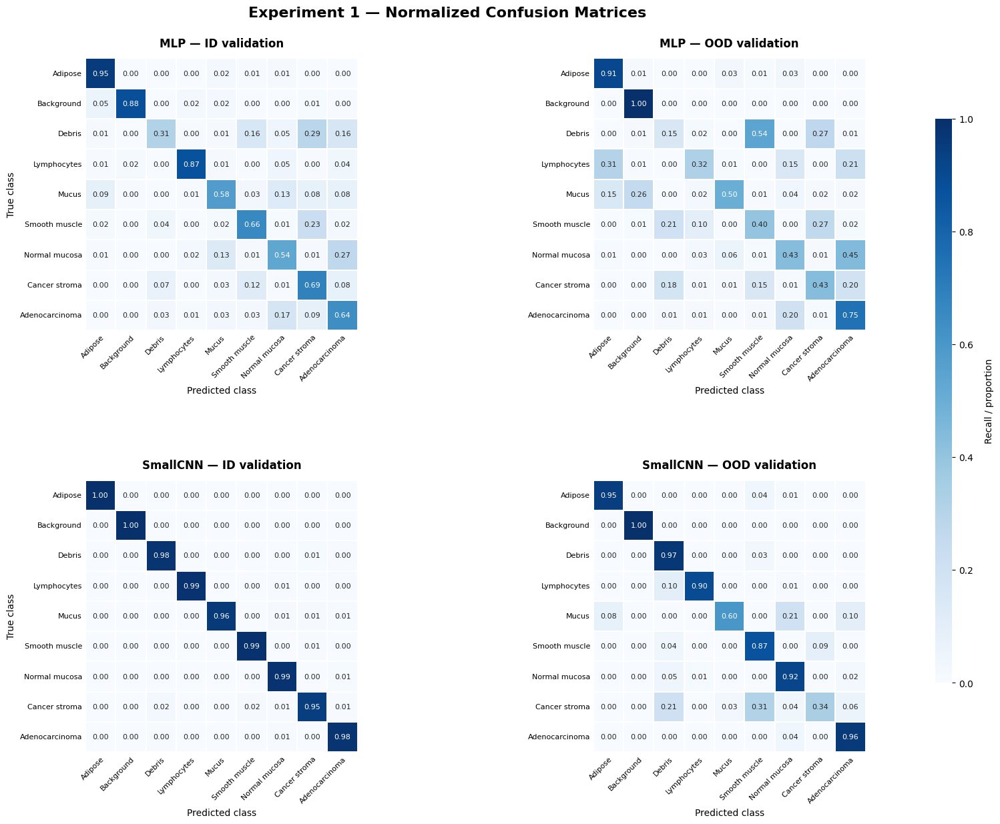

In [31]:
# Experiment 1 — Normalized Confusion Matrices

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Shorter labels for visualization
short_classes = [
    "Adipose",
    "Background",
    "Debris",
    "Lymphocytes",
    "Mucus",
    "Smooth muscle",
    "Normal mucosa",
    "Cancer stroma",
    "Adenocarcinoma"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 13),
    sharex=False,
    sharey=False
)

# Dedicated colorbar axis
cbar_ax = fig.add_axes([0.93, 0.20, 0.015, 0.65])

splits = ["id_val", "ood_val"]
split_titles = ["ID validation", "OOD validation"]

for i, (model_name, model) in enumerate(models.items()):

    for j, split in enumerate(splits):

        loader = make_loader(split)
        preds, labels = predict(model, loader, rgb)

        cm = confusion_matrix(
            labels,
            preds,
            labels=np.arange(len(CLASSES)),
            normalize="true"
        )

        ax = axes[i, j]

        sns.heatmap(
            cm,
            ax=ax,
            cmap="Blues",
            vmin=0,
            vmax=1,
            annot=True,
            fmt=".2f",
            annot_kws={"fontsize": 8},
            xticklabels=short_classes,
            yticklabels=short_classes,
            square=True,
            linewidths=0.3,
            linecolor="white",
            cbar=(i == 0 and j == 0),
            cbar_ax=cbar_ax if (i == 0 and j == 0) else None
        )

        ax.set_title(
            f"{model_name} — {split_titles[j]}",
            fontsize=12,
            fontweight="bold",
            pad=12
        )

        ax.set_xlabel("Predicted class", fontsize=10)
        ax.set_ylabel(
            "True class" if j == 0 else "",
            fontsize=10
        )

        ax.set_xticklabels(
            short_classes,
            rotation=45,
            ha="right",
            rotation_mode="anchor",
            fontsize=8
        )

        ax.set_yticklabels(
            short_classes,
            rotation=0,
            fontsize=8
        )

        ax.tick_params(axis="both", length=0)

fig.suptitle(
    "Experiment 1 — Normalized Confusion Matrices",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.15,
    right=0.90,
    top=0.92,
    bottom=0.12,
    wspace=0.48,
    hspace=0.55
)

cbar_ax.set_ylabel(
    "Recall / proportion",
    fontsize=10,
    labelpad=12
)

plt.show()

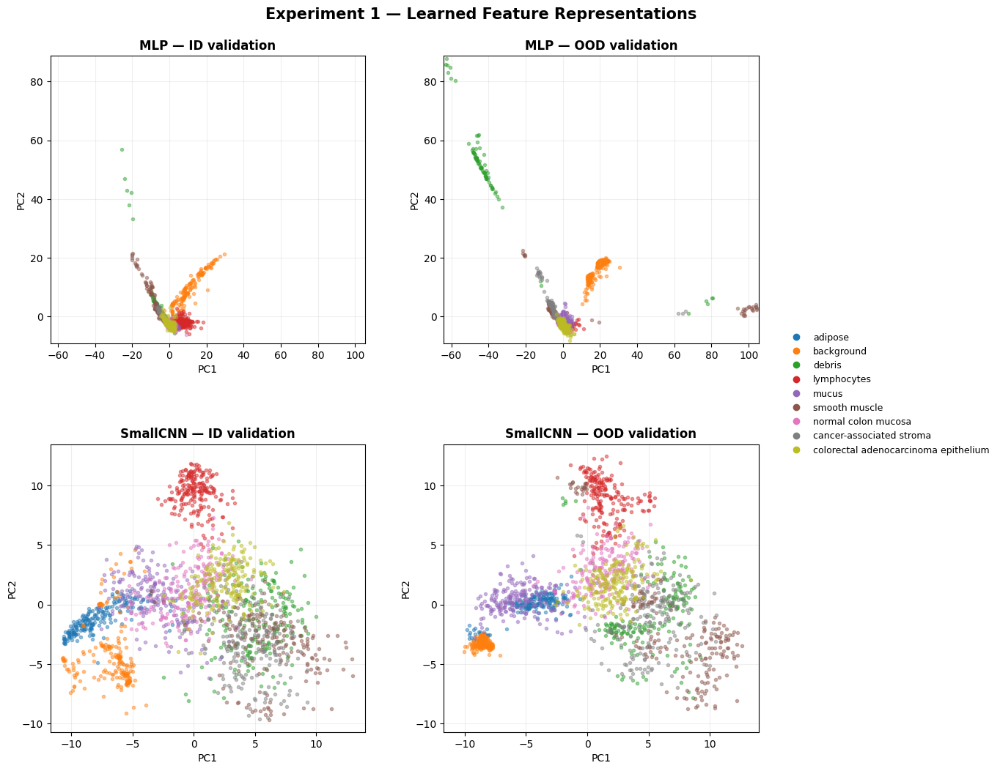

In [32]:
# Experiment 1 — PCA of learned representations

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.lines import Line2D

def extract_representations(model, split, n_per_class=200):
    model.eval()

    X, y = SPLITS[split]
    labels = y.numpy()
    rng = np.random.default_rng(seed)

    indices = np.concatenate([
        rng.choice(
            np.flatnonzero(labels == c),
            size=min(n_per_class, np.sum(labels == c)),
            replace=False
        )
        for c in range(len(CLASSES))
    ])

    loader = DataLoader(
        TensorDataset(X[indices], y[indices]),
        batch_size=128,
        shuffle=False
    )

    features = []
    targets = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = rgb(xb)

            # Remove only the final classification layer
            z = model.network[:-1](xb)

            features.append(z.cpu().numpy())
            targets.append(yb.numpy())

    return np.concatenate(features), np.concatenate(targets)


fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

model_dict = {
    "MLP": mlp,
    "SmallCNN": cnn
}

class_colors = plt.get_cmap("tab10").colors[:len(CLASSES)]

for i, (name, model) in enumerate(model_dict.items()):

    Z_id, y_id = extract_representations(model, "id_val")
    Z_ood, y_ood = extract_representations(model, "ood_val")

    # Fit scaler and PCA on ID features only
    scaler = StandardScaler()
    Z_id_scaled = scaler.fit_transform(Z_id)
    Z_ood_scaled = scaler.transform(Z_ood)

    pca = PCA(n_components=2, random_state=seed)
    P_id = pca.fit_transform(Z_id_scaled)
    P_ood = pca.transform(Z_ood_scaled)

    for j, (P, labels, split) in enumerate([
        (P_id, y_id, "ID validation"),
        (P_ood, y_ood, "OOD validation")
    ]):

        ax = axes[i, j]

        for c in range(len(CLASSES)):
            mask = labels == c

            ax.scatter(
                P[mask, 0],
                P[mask, 1],
                s=9,
                alpha=0.45,
                color=class_colors[c],
                rasterized=True
            )

        ax.set_title(
            f"{name} — {split}",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.grid(alpha=0.2)

    # Same coordinate limits within each model
    combined = np.vstack([P_id, P_ood])

    for ax in axes[i]:
        ax.set_xlim(
            combined[:, 0].min() - 1,
            combined[:, 0].max() + 1
        )
        ax.set_ylim(
            combined[:, 1].min() - 1,
            combined[:, 1].max() + 1
        )

# Shared external legend
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        color=class_colors[c],
        label=CLASSES[c],
        markersize=6
    )
    for c in range(len(CLASSES))
]

fig.legend(
    handles=handles,
    loc="center left",
    bbox_to_anchor=(0.79, 0.50),
    frameon=False,
    fontsize=9
)

fig.suptitle(
    "Experiment 1 — Learned Feature Representations",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.08,
    right=0.77,
    top=0.92,
    bottom=0.08,
    wspace=0.25,
    hspace=0.35
)

plt.show()


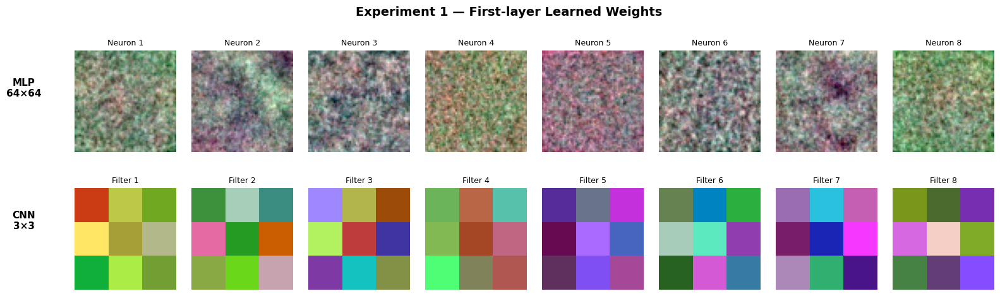

In [33]:
# Experiment 1 — First-layer weights: MLP vs SmallCNN

import numpy as np
import matplotlib.pyplot as plt

# MLP: first Linear layer, shape (512, 12288)
mlp_weights = (
    mlp.network[1].weight
    .detach().cpu().numpy()
)

# CNN: first convolution, shape (32, 3, 3, 3)
cnn_filters = (
    cnn.network[0].weight
    .detach().cpu().numpy()
)

fig, axes = plt.subplots(
    2, 8,
    figsize=(16, 5)
)

# First eight MLP neurons
for i in range(8):
    w = mlp_weights[i].reshape(3, 64, 64)
    w = np.transpose(w, (1, 2, 0))

    # Center around zero, using a symmetric scale
    scale = max(np.abs(w).max(), 1e-8)

    axes[0, i].imshow(
        np.clip(w / (2 * scale) + 0.5, 0, 1)
    )

    axes[0, i].set_title(f"Neuron {i+1}", fontsize=9)
    axes[0, i].axis("off")

# First eight CNN filters
for i in range(8):
    f = cnn_filters[i].transpose(1, 2, 0)

    scale = max(np.abs(f).max(), 1e-8)

    axes[1, i].imshow(
        np.clip(f / (2 * scale) + 0.5, 0, 1),
        interpolation="nearest"
    )

    axes[1, i].set_title(f"Filter {i+1}", fontsize=9)
    axes[1, i].axis("off")

fig.text(
    0.02, 0.72,
    "MLP\n64×64",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

fig.text(
    0.02, 0.30,
    "CNN\n3×3",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

fig.suptitle(
    "Experiment 1 — First-layer Learned Weights",
    fontsize=14,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.84,
    bottom=0.08,
    wspace=0.15,
    hspace=0.35
)

plt.show()


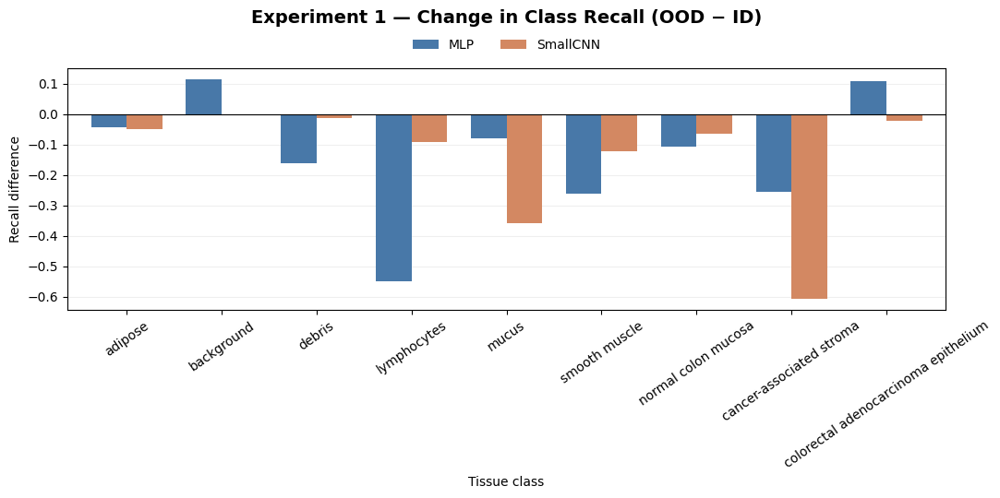

In [34]:
# Experiment 1 — Per-class recall change from ID to OOD

recall_change = (
    recall_df.pivot_table(
        index="class",
        columns=["model", "split"],
        values="recall"
    )
    .reindex(CLASSES)
)

delta = pd.DataFrame({
    model: (
        recall_change[(model, "ood_val")]
        - recall_change[(model, "id_val")]
    )
    for model in ["MLP", "SmallCNN"]
})

fig, ax = plt.subplots(figsize=(11, 5.5))

delta.plot(
    kind="bar",
    ax=ax,
    color=["#4878A8", "#D38862"],
    width=0.75
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(
    "Experiment 1 — Change in Class Recall (OOD − ID)",
    fontsize=14,
    fontweight="bold",
    pad=35
)

ax.set_xlabel("Tissue class")
ax.set_ylabel("Recall difference")
ax.tick_params(axis="x", rotation=35)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Design justification

> **Question.** (0.5 pt)
>
> Why does comparing an MLP and a SmallCNN, trained from scratch on the same patches, with the same loop and the same
> evaluation splits, isolate the contribution of the convolutional inductive bias? Which factors did you keep fixed,
> and which differences between the two models (besides the inductive bias) could still explain the results?
>
> Which metrics did you use to test the hypothesis, and why do they answer the question?

Comparing an MLP and a SmallCNN trained from scratch on the same histopathology patches allows us to investigate the contribution of convolutional inductive bias. Both models solve the same nine-class classification task, use identical input images and RGB preprocessing, and are evaluated on the same in-distribution (ID) and out-of-distribution (OOD) validation splits.

To ensure a controlled comparison, we used the same training dataset, batch size (128), Adam optimizer, maximum number of epochs (15), training loop, loss function (CrossEntropyLoss), and checkpoint selection criterion (best ID validation balanced accuracy). Both architectures received an equal hyperparameter search budget of three configurations, selected exclusively through ID validation.

Nevertheless, the architectures differ in more than convolutional inductive bias. The MLP contains 6,425,609 trainable parameters, compared with only 94,857 in the SmallCNN (approximately 67.7 times fewer). The selected configurations also differ: the MLP uses a learning rate of 0.0003 and dropout of 0.5, whereas the CNN uses a learning rate of 0.001, BatchNorm, and global average pooling. These differences in regularization, optimization, parameter efficiency, and computational cost may also contribute to the observed performance gap. Consequently, the experiment provides strong comparative evidence, but does not perfectly isolate convolution as the sole causal factor.

We used **ID balanced accuracy, OOD balanced accuracy, and the ID–OOD balanced accuracy gap** as our primary evaluation metrics. Balanced accuracy gives equal importance to all nine tissue classes, which is particularly relevant because our EDA identified substantial changes in class proportions across centers.

ID balanced accuracy measures how effectively each architecture learns the classification task within the training domain, whereas OOD balanced accuracy measures its ability to transfer to a new clinical center. Finally, the ID–OOD gap quantifies the change in balanced accuracy between centers, providing a complementary measure of generalization stability.

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of the MLP and of the SmallCNN. Address the following points:
>
> Do the results support or contradict the hypothesis? Refer to specific numbers (ID and OOD balanced accuracy, gap).
>
> Compare the learning curves of the two models. Did the MLP use its extra parameters to fit the training set better?
> What does that say about the relation between the number of parameters and generalization?
>
> Which classes lose the most on the new center, for each model? What do the first-layer weights of the MLP and the
> filters of the CNN look like, and does what each model learned help to explain its behavior on the new center?

#### Hypothesis evaluation and generalization performance

The results support the hypothesis that convolutional inductive bias improves classification and generalization across clinical centers. Despite having approximately 68 times fewer parameters, the SmallCNN achieves substantially higher balanced accuracy than the MLP on both ID (98.28% vs. 67.83%) and OOD validation (87.22% vs. 55.58%). The CNN also exhibits a slightly smaller ID–OOD gap (11.06 vs. 12.25 percentage points). Thus, all three predictions are supported, although the modest gap reduction (1.19 percentage points) indicates that the strongest evidence lies in the CNN's superior absolute performance rather than substantially greater stability across centers.

#### Learning curves and model capacity

The learning curves show that the SmallCNN converges considerably faster, reducing its training loss from approximately 0.43 to 0.05 and reaching nearly 98% training accuracy. In contrast, the MLP's loss decreases from approximately 1.36 to 0.80, with training accuracy remaining near 69%. Therefore, the MLP did not use its additional parameters to fit the training data better; instead, its behavior suggests underfitting or optimization limitations under the tested conditions. This demonstrates that parameter count alone does not determine performance: the CNN's locality, weight sharing, and hierarchical feature extraction provide more suitable inductive biases for histopathology. However, the CNN requires substantially more training time (2,525 vs. 157 seconds), showing that fewer parameters do not necessarily imply lower computational cost.

#### Per-class performance and distribution shift

The largest OOD deterioration for the MLP occurs in lymphocytes, whose recall drops from 0.87 to 0.28, followed by cancer-associated stroma (0.69 to 0.43) and smooth muscle (0.67 to 0.46). Its confusion matrix also reveals frequent misclassifications of debris and normal colon mucosa. For the CNN, the greatest decline occurs in cancer-associated stroma (1.00 to 0.56), frequently confused with smooth muscle (26%), followed by adipose (1.00 to 0.78) and smooth muscle (0.98 to 0.81). Nevertheless, the CNN maintains high OOD recall for lymphocytes (0.99), debris (0.94), and adenocarcinoma epithelium (0.97), indicating stronger class discrimination despite the distribution shift.

#### Learned weights and feature representations

The MLP's first-layer weights exhibit diffuse, noisy, and color-dependent patterns spanning the entire 64×64 patch, consistent with its position-specific connections. In contrast, the CNN learns compact 3×3 filters, shared across spatial positions, that capture elementary color and local intensity patterns. PCA projections further reveal that the MLP's learned representations exhibit substantial overlap and pronounced ID–OOD shifts, whereas the CNN produces more structured class groupings that remain partially recognizable across centers. These observations are consistent with the CNN learning more transferable features, although neither the filter visualizations nor the two-dimensional PCA projections prove which properties determine its predictions.

#### Final conclusion

Overall, the hypothesis is supported: the SmallCNN significantly outperforms the MLP on both ID and OOD validation, despite using approximately 68 times fewer parameters. The results suggest that convolutional locality, weight sharing, and hierarchical representations are better suited to recognizing spatially distributed histological patterns than fully connected layers operating on flattened pixels. However, the remaining OOD degradation, particularly for cancer-associated stroma, confirms that convolutional structure alone does not guarantee robustness to changes between clinical centers.

---

## Experiment 2: Does the Network Know That a Patch Has No "Up"?

A tissue patch has no canonical orientation: rotated by 90°, 180° or 270°, or mirrored, a patch of smooth muscle is
still smooth muscle. These 8 transformations (4 rotations, each with or without a mirror) are **symmetries of the
task**.

Neither architecture has this symmetry built in. An MLP ties each weight to a pixel position, and the filters of a CNN
are oriented: a filter that detects vertical edges does not respond to horizontal ones, so a rotated patch produces
different feature maps. In Lecture 18, a CNN was more tolerant to shifts than an MLP, but it became robust to them
only after **data augmentation** showed it shifted images during training: *convolution gives the network the ability
to detect a pattern anywhere; augmentation teaches it to use that ability*.

The code below provides the 8 symmetries as functions on a batch of images, and an augmentation that applies one of
them, chosen at random, to each training patch.

> **Question:**
>
> Are the models of Experiment 1 invariant to rotations and mirroring of the patch? Does training with these
> symmetries as data augmentation make the MLP and the CNN invariant, and does it reduce the ID–OOD gap?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis. It should predict (i) how the balanced accuracy of the Experiment 1 models changes
> when the evaluation patches are rotated or mirrored, and whether the MLP and the CNN differ, and (ii) the direction
> of the change in OOD balanced accuracy and in the ID–OOD gap when each architecture is trained with the symmetries
> as augmentation. Relate your prediction to the structural properties of each architecture.*

We hypothesize that neither the MLP nor the SmallCNN trained in Experiment 1 is fully invariant to rotations and reflections, resulting in lower balanced accuracy when evaluated on transformed patches. However, we expect the MLP to be more sensitive to these transformations because its weights are tied to absolute positions, whereas the CNN's local filters and weight sharing may provide some robustness to spatial variations, although not explicit rotational or reflection invariance.

Training with the eight symmetry transformations as data augmentation should improve the robustness of both architectures, reducing the variation in balanced accuracy across transformed versions of the same patches. **We expect the CNN to benefit more effectively from augmentation**, since its shared filters can learn local patterns in multiple orientations and reuse them throughout the image.

Consequently, we predict that augmentation will **increase OOD balanced accuracy and reduce the ID–OOD generalization gap for both models**, with the CNN maintaining superior overall performance. This hypothesis would be contradicted if augmentation fails to improve performance on transformed patches, decreases OOD balanced accuracy, or produces an equal or larger ID–OOD gap compared with the corresponding non-augmented models.

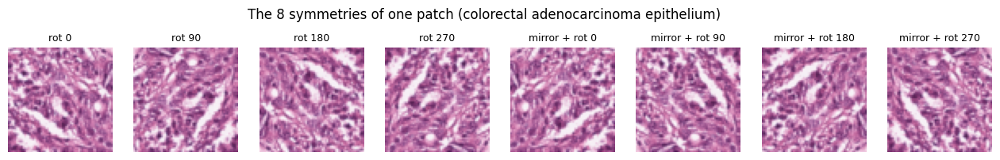

In [35]:
# The 8 symmetries of the square, as functions on a batch of images with shape (batch, channels, height, width).
SYMMETRIES = {
    f"{'mirror + ' if mirror else ''}rot {90 * k}": (
        lambda x, k=k, mirror=mirror: torch.rot90(x.flip(3) if mirror else x, k, dims=(2, 3))
    )
    for mirror in (False, True)
    for k in range(4)
}


def random_symmetry(x: torch.Tensor) -> torch.Tensor:
    # Augmentation: applies one of the 8 symmetries, chosen at random for each image, to a batch (N, C, H, W).
    mirror = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(mirror[:, None, None, None], x.flip(3), x)
    k = torch.randint(4, (len(x),), device=x.device)
    out = x.clone()
    for r in range(1, 4):
        out[k == r] = torch.rot90(x[k == r], r, dims=(2, 3))
    return out


# One OOD validation patch under the 8 symmetries
X, y = SPLITS["ood_val"]
patch = X[:1].float().div(255)
fig, axs = plt.subplots(1, len(SYMMETRIES), figsize=(16, 2.4))
for ax, (name, fn) in zip(axs, SYMMETRIES.items()):
    ax.imshow(fn(patch)[0].permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.suptitle(f"The 8 symmetries of one patch ({CLASSES[y[0].item()]})", fontsize=12)
plt.show()

In [36]:
# Experiment 2 — Part (i)
# Evaluate Experiment 1 models under all 8 symmetries, no retraining or OOD-based model selection.

exp2_symmetry_records = []

baseline_models = {
    "MLP (Exp. 1)": mlp,
    "SmallCNN (Exp. 1)": cnn
}

ood_loader = make_loader("ood_val")

for model_name, model in baseline_models.items():

    print(f"\n{model_name}")

    for symmetry_name, transform in SYMMETRIES.items():

        metrics = evaluate(
            model,
            ood_loader,
            rgb,
            input_fn=transform
        )

        exp2_symmetry_records.append({
            "model": model_name,
            "symmetry": symmetry_name,
            "acc": metrics["acc"],
            "bal_acc": metrics["bal_acc"]
        })

        print(
            f"{symmetry_name:20s} | "
            f"OOD bal. acc: {metrics['bal_acc']:.4f}"
        )

exp2_baseline_symmetries = pd.DataFrame(
    exp2_symmetry_records
)

display(
    exp2_baseline_symmetries.pivot(
        index="symmetry",
        columns="model",
        values="bal_acc"
    ).round(4)
)



MLP (Exp. 1)
rot 0                | OOD bal. acc: 0.5446
rot 90               | OOD bal. acc: 0.5519
rot 180              | OOD bal. acc: 0.5527
rot 270              | OOD bal. acc: 0.5390
mirror + rot 0       | OOD bal. acc: 0.5397
mirror + rot 90      | OOD bal. acc: 0.5435
mirror + rot 180     | OOD bal. acc: 0.5368
mirror + rot 270     | OOD bal. acc: 0.5395

SmallCNN (Exp. 1)
rot 0                | OOD bal. acc: 0.8341
rot 90               | OOD bal. acc: 0.8498
rot 180              | OOD bal. acc: 0.8406
rot 270              | OOD bal. acc: 0.8524
mirror + rot 0       | OOD bal. acc: 0.8527
mirror + rot 90      | OOD bal. acc: 0.8403
mirror + rot 180     | OOD bal. acc: 0.8502
mirror + rot 270     | OOD bal. acc: 0.8444


model,MLP (Exp. 1),SmallCNN (Exp. 1)
symmetry,,
mirror + rot 0,0.5397,0.8527
mirror + rot 180,0.5368,0.8502
mirror + rot 270,0.5395,0.8444
mirror + rot 90,0.5435,0.8403
rot 0,0.5446,0.8341
rot 180,0.5527,0.8406
rot 270,0.5390,0.8524
rot 90,0.5519,0.8498


In [37]:
# Experiment 2 — Part (ii)
# Train new models from scratch with symmetry augmentation.

# -----------------------------------------------
# 1. MLP with symmetry augmentation
# -----------------------------------------------

torch.manual_seed(seed)

mlp_aug = MLP(
    input_size=3 * 64 * 64,
    hidden_sizes=[512, 256],
    dropout=best_mlp_config["dropout"]
).to(DEVICE)

mlp_aug_optimizer = optim.Adam(
    mlp_aug.parameters(),
    lr=best_mlp_config["learning_rate"]
)

mlp_aug_loader = make_loader(
    "train",
    batch_size=128,
    shuffle=True,
    shuffle_seed=seed
)

mlp_aug_history = fit(
    mlp_aug,
    mlp_aug_loader,
    id_val_loader,
    mlp_aug_optimizer,
    n_epochs,
    preprocess=rgb,
    augment=random_symmetry,
    verbose=True
)

report(
    "MLP + symmetry (Exp. 2)",
    mlp_aug,
    rgb,
    mlp_aug_history
)


# -----------------------------------------------
# 2. SmallCNN with symmetry augmentation
# -----------------------------------------------

torch.manual_seed(seed)

cnn_aug = SmallCNN().to(DEVICE)

cnn_aug_optimizer = optim.Adam(
    cnn_aug.parameters(),
    lr=best_cnn_config["learning_rate"]
)

cnn_aug_loader = make_loader(
    "train",
    batch_size=128,
    shuffle=True,
    shuffle_seed=seed
)

cnn_aug_history = fit(
    cnn_aug,
    cnn_aug_loader,
    id_val_loader,
    cnn_aug_optimizer,
    n_epochs,
    preprocess=rgb,
    augment=random_symmetry,
    verbose=True
)

report(
    "SmallCNN + symmetry (Exp. 2)",
    cnn_aug,
    rgb,
    cnn_aug_history
)


# -----------------------------------------------
# 3. Evaluate both augmented models under
#    all 8 OOD symmetries
# -----------------------------------------------

augmented_models = {
    "MLP + symmetry (Exp. 2)": mlp_aug,
    "SmallCNN + symmetry (Exp. 2)": cnn_aug
}

for model_name, model in augmented_models.items():

    print(f"\n{model_name}")

    for symmetry_name, transform in SYMMETRIES.items():

        metrics = evaluate(
            model,
            ood_loader,
            rgb,
            input_fn=transform
        )

        exp2_symmetry_records.append({
            "model": model_name,
            "symmetry": symmetry_name,
            "acc": metrics["acc"],
            "bal_acc": metrics["bal_acc"]
        })

        print(
            f"{symmetry_name:20s} | "
            f"OOD bal. acc: {metrics['bal_acc']:.4f}"
        )

exp2_symmetry_df = pd.DataFrame(
    exp2_symmetry_records
)


Epoch  1/15 | train loss 1.3678 | train acc 0.4560 | val acc 0.5873 | val bal acc 0.5671
Epoch  2/15 | train loss 1.1682 | train acc 0.5401 | val acc 0.5791 | val bal acc 0.5591
Epoch  3/15 | train loss 1.1041 | train acc 0.5703 | val acc 0.6303 | val bal acc 0.6175
Epoch  4/15 | train loss 1.0666 | train acc 0.5872 | val acc 0.6465 | val bal acc 0.6335
Epoch  5/15 | train loss 1.0426 | train acc 0.5979 | val acc 0.6427 | val bal acc 0.6330
Epoch  6/15 | train loss 1.0237 | train acc 0.6070 | val acc 0.6433 | val bal acc 0.6271
Epoch  7/15 | train loss 1.0065 | train acc 0.6141 | val acc 0.6429 | val bal acc 0.6302
Epoch  8/15 | train loss 0.9939 | train acc 0.6187 | val acc 0.6614 | val bal acc 0.6451
Epoch  9/15 | train loss 0.9817 | train acc 0.6238 | val acc 0.6685 | val bal acc 0.6617
Epoch 10/15 | train loss 0.9736 | train acc 0.6280 | val acc 0.6667 | val bal acc 0.6692
Epoch 11/15 | train loss 0.9626 | train acc 0.6300 | val acc 0.6697 | val bal acc 0.6657
Epoch 12/15 | train l

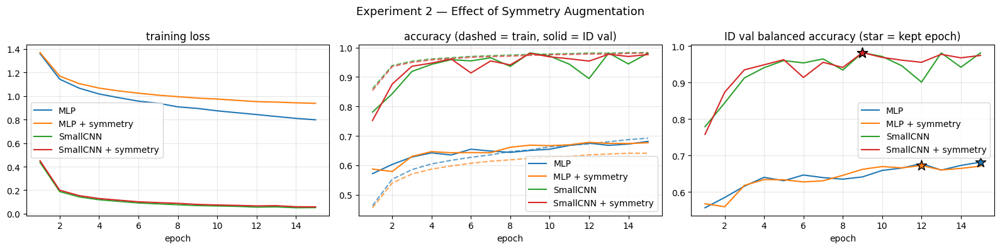

In [38]:
# Experiment 2 — Learning curves

exp2_histories = {
    "MLP": mlp_history,
    "MLP + symmetry": mlp_aug_history,
    "SmallCNN": cnn_history,
    "SmallCNN + symmetry": cnn_aug_history
}

plot_histories(
    exp2_histories,
    title="Experiment 2 — Effect of Symmetry Augmentation"
)

model,MLP (Exp. 1),MLP + symmetry (Exp. 2),SmallCNN (Exp. 1),SmallCNN + symmetry (Exp. 2)
symmetry,,,,
rot 0,0.5446,0.5754,0.8341,0.8876
rot 90,0.5519,0.5762,0.8498,0.9040
rot 180,0.5527,0.5731,0.8406,0.8858
rot 270,0.5390,0.5748,0.8524,0.9038
mirror + rot 0,0.5397,0.5750,0.8527,0.8921
mirror + rot 90,0.5435,0.5775,0.8403,0.8830
mirror + rot 180,0.5368,0.5724,0.8502,0.8889
mirror + rot 270,0.5395,0.5797,0.8444,0.8875


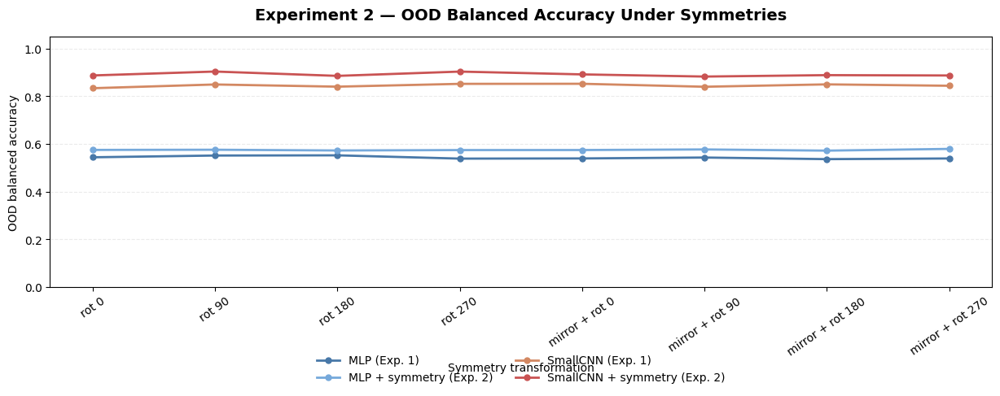

In [39]:
# Experiment 2 — OOD balanced accuracy under each symmetry

symmetry_order = list(SYMMETRIES.keys())

symmetry_table = exp2_symmetry_df.pivot(
    index="symmetry",
    columns="model",
    values="bal_acc"
).reindex(symmetry_order)

display(symmetry_table.round(4))

fig, ax = plt.subplots(figsize=(13, 5.5))

model_colors = {
    "MLP (Exp. 1)": "#4878A8",
    "MLP + symmetry (Exp. 2)": "#76A9DB",
    "SmallCNN (Exp. 1)": "#D38862",
    "SmallCNN + symmetry (Exp. 2)": "#C95353"
}

for model_name in symmetry_table.columns:

    ax.plot(
        symmetry_order,
        symmetry_table[model_name],
        marker="o",
        linewidth=2,
        markersize=5,
        label=model_name,
        color=model_colors[model_name]
    )

ax.set_title(
    "Experiment 2 — OOD Balanced Accuracy Under Symmetries",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Symmetry transformation")
ax.set_ylabel("OOD balanced accuracy")

ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=35)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.23),
    ncol=2,
    frameon=False
)

fig.subplots_adjust(
    top=0.90,
    bottom=0.34,
    left=0.08,
    right=0.97
)

plt.show()

,params,id_bal_acc,ood_bal_acc,gap_bal_acc,train_time_s
MLP (Exp. 1),6425609.0,0.6812,0.5446,0.1367,55.0
MLP + symmetry (Exp. 2),6425609.0,0.6720,0.5754,0.0966,66.0
SmallCNN (Exp. 1),94857.0,0.9814,0.8341,0.1473,317.0
SmallCNN + symmetry (Exp. 2),94857.0,0.9816,0.8876,0.0940,321.0


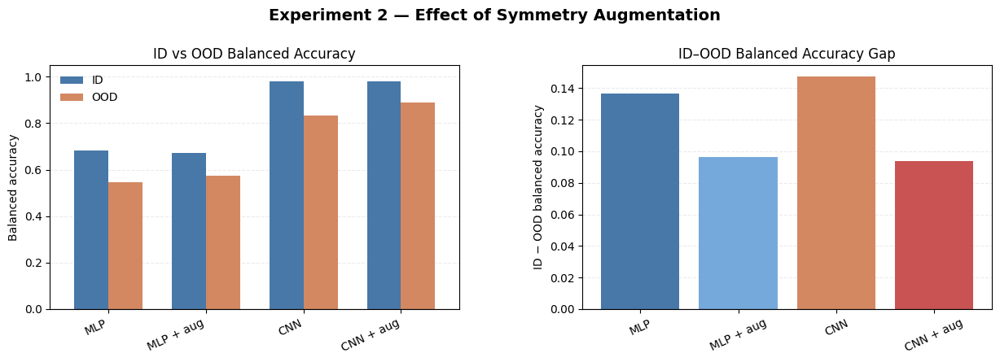

In [40]:
# Experiment 2 — ID/OOD performance and generalization gap

model_names = [
    "MLP (Exp. 1)",
    "MLP + symmetry (Exp. 2)",
    "SmallCNN (Exp. 1)",
    "SmallCNN + symmetry (Exp. 2)"
]

exp2_results = pd.DataFrame({
    name: RESULTS[name]
    for name in model_names
}).T

display(
    exp2_results[
        ["params", "id_bal_acc", "ood_bal_acc",
         "gap_bal_acc", "train_time_s"]
    ].round(4)
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

short_names = [
    "MLP",
    "MLP + aug",
    "CNN",
    "CNN + aug"
]

# Balanced accuracy
exp2_results[
    ["id_bal_acc", "ood_bal_acc"]
].plot(
    kind="bar",
    ax=axes[0],
    color=["#4878A8", "#D38862"],
    width=0.7
)

axes[0].set_title("ID vs OOD Balanced Accuracy")
axes[0].set_ylabel("Balanced accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].set_xticklabels(short_names, rotation=25, ha="right")
axes[0].legend(["ID", "OOD"], frameon=False)

# Generalization gap
axes[1].bar(
    short_names,
    exp2_results["gap_bal_acc"],
    color=["#4878A8", "#76A9DB", "#D38862", "#C95353"]
)

axes[1].set_title("ID–OOD Balanced Accuracy Gap")
axes[1].set_ylabel("ID − OOD balanced accuracy")
axes[1].tick_params(axis="x", rotation=25)

for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Experiment 2 — Effect of Symmetry Augmentation",
    fontsize=14,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.08,
    right=0.97,
    top=0.85,
    bottom=0.25,
    wspace=0.30
)

plt.show()

In [41]:
# Experiment 2 — Prediction consistency across 8 symmetries

all_models = {
    **baseline_models,
    **augmented_models
}

consistency_rows = []

for model_name, model in all_models.items():

    predictions = []

    for transform in SYMMETRIES.values():

        preds, labels = predict(
            model,
            ood_loader,
            rgb,
            input_fn=transform
        )

        predictions.append(preds)

    predictions = np.stack(predictions, axis=0)

    # Fraction of patches receiving exactly the same
    # predicted class under all eight transformations.
    consistent = np.all(
        predictions == predictions[0:1],
        axis=0
    )

    consistency_rows.append({
        "model": model_name,
        "prediction_consistency": consistent.mean()
    })

consistency_df = pd.DataFrame(consistency_rows)

display(consistency_df.round(4))

,model,prediction_consistency
0,MLP (Exp. 1),0.5192
1,SmallCNN (Exp. 1),0.8510
2,MLP + symmetry (Exp. 2),0.7318
3,SmallCNN + symmetry (Exp. 2),0.8994


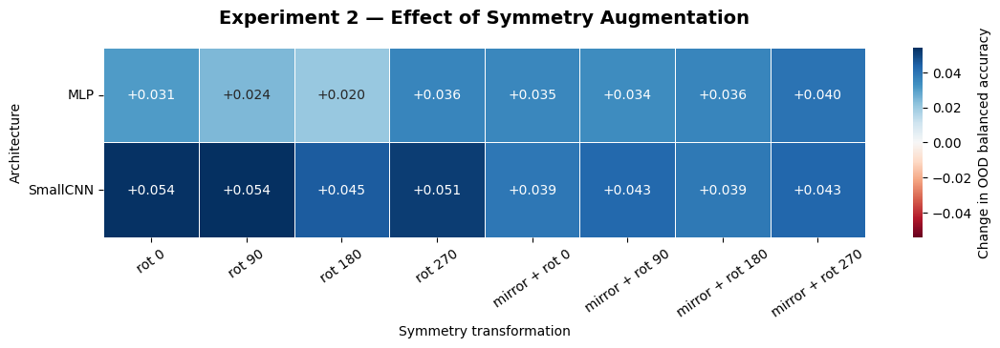

In [42]:
# Experiment 2 — Effect of augmentation by symmetry

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

symmetry_order = list(SYMMETRIES.keys())

# Use the results already computed in Experiment 2
symmetry_scores = exp2_symmetry_df.pivot(
    index="symmetry",
    columns="model",
    values="bal_acc"
).reindex(symmetry_order)

# Improvement in balanced accuracy after augmentation
delta_mlp = (
    symmetry_scores["MLP + symmetry (Exp. 2)"]
    - symmetry_scores["MLP (Exp. 1)"]
)

delta_cnn = (
    symmetry_scores["SmallCNN + symmetry (Exp. 2)"]
    - symmetry_scores["SmallCNN (Exp. 1)"]
)

improvement_df = pd.DataFrame({
    "MLP": delta_mlp,
    "SmallCNN": delta_cnn
}).T

# Symmetric color scale around zero
limit = max(
    np.abs(improvement_df.to_numpy()).max(),
    1e-6
)

fig, ax = plt.subplots(figsize=(12, 3.5))

sns.heatmap(
    improvement_df,
    ax=ax,
    cmap="RdBu",
    center=0,
    vmin=-limit,
    vmax=limit,
    annot=True,
    fmt="+.3f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Change in OOD balanced accuracy"
    }
)

ax.set_title(
    "Experiment 2 — Effect of Symmetry Augmentation",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Symmetry transformation")
ax.set_ylabel("Architecture")

ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)

fig.subplots_adjust(
    left=0.13,
    right=0.96,
    top=0.82,
    bottom=0.25
)

plt.show()

### Design justification

> **Question.** (0.5 pt)
>
> Explain your experiment configuration: what remained the same as in Experiment 1 and what changed. Why does
> evaluating a model on transformed copies of the same patches measure its invariance? Why is the augmentation the only
> difference between the two trainings of each architecture? How does your experiment answer the question?

To investigate rotational and reflection invariance, we evaluated the original MLP and SmallCNN from Experiment 1 on the same OOD validation patches under all eight symmetries (four rotations, with or without mirroring), without retraining. Since these transformations preserve tissue identity, changes in predictions or balanced accuracy reveal sensitivity to orientation rather than changes in the underlying classification task.

We then trained new instances of both architectures from scratch, introducing `random_symmetry` only during training. For each architecture, we preserved the original network structure, dataset, RGB preprocessing, batch size (128), Adam optimizer, learning rate, maximum number of epochs (15), and ID validation checkpoint selection criterion. The MLP also retained its dropout of 0.5. Thus, **symmetry augmentation was the only intentional change in the training configuration**.

We compared balanced accuracy across all transformations, prediction consistency, ID and OOD balanced accuracy, and the ID–OOD gap. Together, these metrics distinguish robustness to geometric transformations from generalization across clinical centers. Prediction consistency directly measures whether the same patch receives identical predictions under all eight symmetries, while balanced accuracy verifies whether these predictions remain correct.

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of the symmetry experiment. Address the following points:
>
> Were the models of Experiment 1 invariant to the symmetries? Did the MLP and the CNN behave differently? Refer to
> specific numbers.
>
> Did augmentation make each architecture invariant? Did it help the CNN and the MLP equally? Relate your answer to the
> sentence from Lecture 18 quoted above.
>
> Did augmentation change the ID–OOD gap? Augmentation also acts as a regularizer, because the model rarely sees
> exactly the same image twice. Can you attribute the change in OOD performance to the invariance itself, rather than
> to less overfitting?

**1. Invariance of the Original Models**

The Experiment 1 models exhibit relatively stable OOD balanced accuracy across the eight symmetries, ranging from **54.62% to 55.63% for the MLP** and **87.22% to 88.72% for the SmallCNN**. However, stable aggregate accuracy does not imply invariance for individual patches. Prediction consistency reveals that only **54.48% of patches receive identical predictions under all transformations for the MLP**, compared with **84.99% for the CNN**. Thus, neither architecture is fully invariant, although the CNN demonstrates substantially greater inherent robustness, consistent with its local connectivity and weight sharing.

**2. Effects of Symmetry Augmentation**

Augmentation improves prediction consistency considerably, from **54.48% to 72.79% for the MLP** (+18.31 percentage points) and from **84.99% to 92.31% for the CNN** (+7.32 points). The MLP therefore benefits more in relative terms, although the CNN remains substantially more consistent. OOD balanced accuracy also increases from **55.58% to 56.51% for the MLP** and from **87.22% to 87.89% for the CNN**. The symmetry-specific results indicate generally positive but modest accuracy changes, with occasional decreases for the CNN. These findings support Lecture 18's observation that convolution provides useful spatial inductive biases, while augmentation explicitly teaches the network to recognize patterns across transformations. Nevertheless, neither augmented model achieves complete invariance.

**3. Generalization Gap and Learning Curves**

Symmetry augmentation reduces the ID–OOD balanced accuracy gap for both architectures: from **12.25 to 11.01 percentage points for the MLP** and from **11.06 to 10.33 points for the CNN**. ID balanced accuracy remains nearly unchanged, decreasing slightly from 67.83% to 67.52% for the MLP and from 98.28% to 98.22% for the CNN. The augmented MLP also exhibits somewhat higher training loss, while the CNN's learning curves remain broadly similar. This suggests that augmentation introduces additional training difficulty without substantially compromising ID performance. However, the reductions in generalization gap are modest compared with the improvements in prediction consistency.

**4. Interpretation and Conclusion**

The results **partially support the hypothesis**: augmentation substantially improves prediction invariance and slightly increases OOD balanced accuracy while reducing the ID–OOD gap for both architectures. The CNN maintains superior overall performance, whereas the MLP experiences the larger improvement in prediction consistency. However, we cannot attribute the OOD gains exclusively to geometric invariance, because augmentation also acts as a regularizer by exposing models to different versions of training patches and potentially reducing overfitting. Moreover, the EDA identified color and texture shifts that geometric transformations do not directly address. Therefore, symmetry augmentation improves robustness, but its contribution to cross-center generalization is limited and cannot be causally separated from regularization in this experiment.

---

## Experiment 3: Is the Stain Color a Shortcut?

Each center has its own staining protocol and scanner, so the colors of a patch partly encode **where** it was
acquired. A network trained on a single center may learn to recognize a tissue by the exact shades it has in that
center, a **shortcut** that fits the training data but does not transfer to a center whose stains look different,
even if the morphology of the tissue is the same.

There are two opposite ways to prevent a network from relying on the exact colors:
- **remove them**: train and evaluate on grayscale patches. The network cannot use color at all, but it also loses
  the difference between the purple of hematoxylin (nuclei) and the pink of eosin (cytoplasm, fibers), which a
  pathologist uses;
- **randomize them**: keep the colors, but change the amount of each stain at random in every training patch
  (**stain augmentation**, Tellez et al., 2019), so that no exact shade is reliably associated with a class.

`stain_jitter` below converts each RGB patch into the concentrations of hematoxylin, eosin and DAB (the color
deconvolution of `skimage.color.rgb2hed`), multiplies each concentration by a random factor in [1 − `scale`,
1 + `scale`], adds a random shift in [−`shift`, `shift`], and converts back to RGB. Every patch gets its own factors.

> **Question:**
>
> Does the CNN rely on the exact stain colors of the training center? Which strategy reduces the ID–OOD gap more:
> removing color (grayscale) or randomizing the stains during training (stain augmentation)?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis. It should predict the direction of the change in ID balanced accuracy, OOD
> balanced accuracy and ID–OOD gap for each of the two strategies, relative to the CNN of the previous experiments, and
> which strategy is better. Consider both what color reveals about the center and what it reveals about the tissue,
> and relate your prediction to the Data Exploration.*

We hypothesize that **stain augmentation will improve OOD generalization more effectively than greyscale conversion**, because it reduces reliance on center-specific color patterns while preserving diagnostically relevant staining information.

Our EDA revealed class-dependent shifts in RGB and HSV distributions between clinical centers, suggesting that exact stain colors may act as shortcuts. **Training on grayscale patches** should eliminate these color-dependent shortcuts and potentially reduce the ID-OOD gap. However, removing color also discards useful distinctions between hematoxylin-stained nuclei and eosin-stained tissue structures. Therefore, we predict a decrease in ID balanced accuracy and a possible decrease in absolute OOD balanced accuracy, despite a smaller generalization gap.

In contrast, **stain augmentation** preserves color information while exposing the CNN to variations in stain concentrations during training. We expect ID balanced accuracy to remain similar or decrease slightly, OOD balanced accuracy to increase, and the ID–OOD gap to decrease relative to the original RGB CNN. We predict that stain augmentation will achieve the highest OOD balanced accuracy and a smaller gap than grayscale, providing the best balance between discriminative information and robustness to center-specific staining.

This hypothesis would be contradicted if grayscale achieves better OOD balanced accuracy and a smaller gap than stain augmentation, or if stain augmentation fails to improve OOD performance and reduce the generalization gap relative to the original CNN.

In [43]:
# (a) Grayscale: the same gray image in the 3 channels (so the architecture does not change), standardized with
#     statistics of the grayscale training split. Used for training AND evaluation.
def grayscale(x: torch.Tensor) -> torch.Tensor:
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    return gray.expand(-1, 3, -1, -1)


gray = Preprocess(color_fn=grayscale)


# (b) Stain augmentation, for the TRAINING split only (the model is evaluated with `rgb`).
RGB_FROM_HED = torch.tensor([[0.65, 0.70, 0.29],    # hematoxylin
                             [0.07, 0.99, 0.11],    # eosin
                             [0.27, 0.57, 0.78]])   # DAB      (the matrix of skimage.color.rgb2hed)
HED_FROM_RGB = torch.linalg.inv(RGB_FROM_HED)


def stain_jitter(x: torch.Tensor, scale: float = 0.2, shift: float = 0.05) -> torch.Tensor:
    # Random change of the amount of each stain, with its own factors for each image of a batch (N, 3, H, W) in [0, 1].
    optical_density = -torch.log(x.clamp(min=1e-6)).permute(0, 2, 3, 1)           # (N, H, W, 3)
    stains = optical_density @ HED_FROM_RGB.to(x.device)                         # concentrations of H, E and DAB
    factors = 1 + scale * (2 * torch.rand(len(x), 1, 1, 3, device=x.device) - 1)
    shifts = shift * (2 * torch.rand(len(x), 1, 1, 3, device=x.device) - 1)
    stains = stains * factors + shifts
    return torch.exp(-(stains @ RGB_FROM_HED.to(x.device))).clamp(0, 1).permute(0, 3, 1, 2)


# Choose the strength of the augmentation and justify it: the default values are only a starting point.
# Example of use: fit(..., preprocess=rgb, augment=stain_jitter). If you start from Experiment 2, combine both:
# augment=lambda x: random_symmetry(stain_jitter(x)).

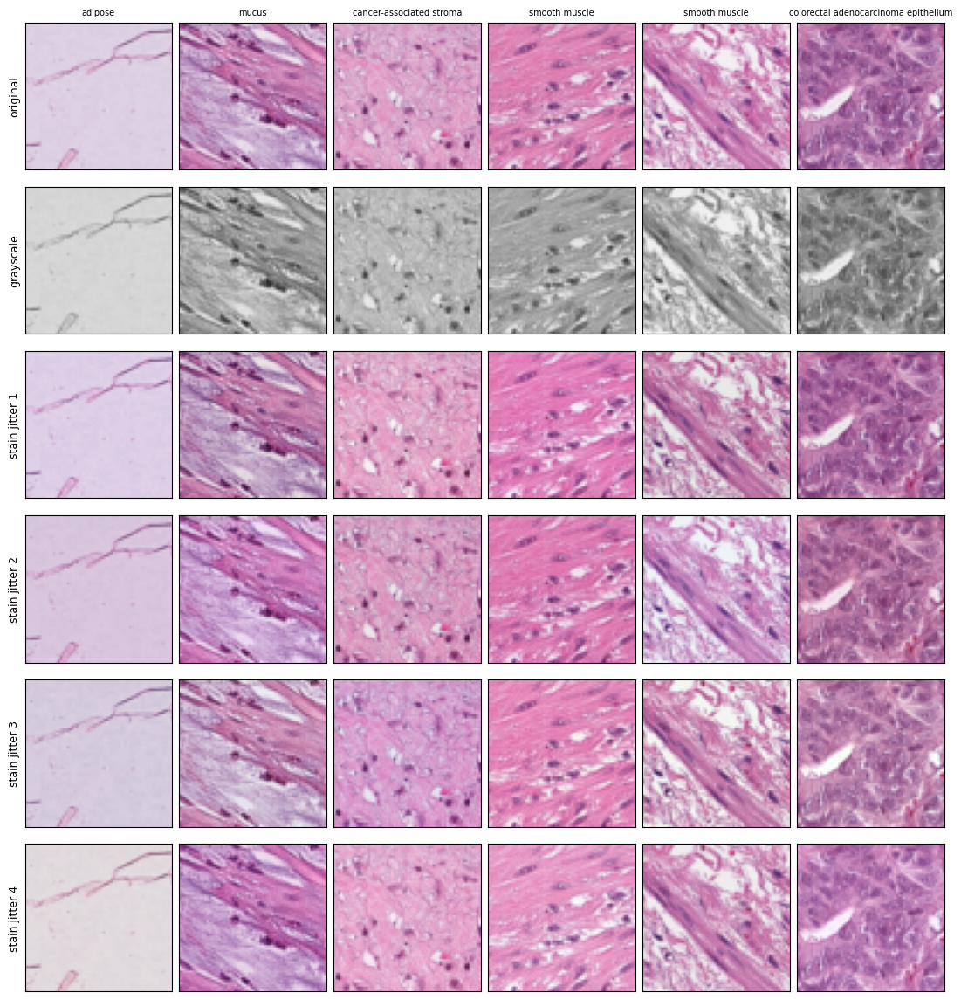

In [44]:
# The same training patches: original, grayscale and four draws of stain augmentation
X, y = SPLITS["train"]
patches = X[:6].float().div(255)
torch.manual_seed(seed)
rows = {"original": patches, "grayscale": grayscale(patches)}
rows.update({f"stain jitter {k + 1}": stain_jitter(patches) for k in range(4)})

fig, axs = plt.subplots(len(rows), len(patches), figsize=(1.8 * len(patches), 1.9 * len(rows)), constrained_layout=True)
for i, (name, batch) in enumerate(rows.items()):
    for j in range(len(patches)):
        axs[i, j].imshow(batch[j].permute(1, 2, 0).numpy())
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        if i == 0:
            axs[i, j].set_title(CLASSES[y[j].item()], fontsize=7)
    axs[i, 0].set_ylabel(name, fontsize=9)
plt.show()

In [45]:
# Your code here: start from the SmallCNN configuration of Experiment 1 or 2 (state which one) and change ONLY the
# color processing, so that the effect of color is isolated. Train the grayscale CNN and the stain-augmented CNN,
# evaluate them with report() (gray for the grayscale CNN, rgb for the stain-augmented one) and analyze.

In [46]:
# Experiment 3 — Is the Stain Color a Shortcut?
# Baseline: SmallCNN from Experiment 1 (no geometric augmentation).
# Only color processing changes.

# --------------------------------------------------
# 1. Experimental configuration
# --------------------------------------------------

exp3_lr = best_cnn_config["learning_rate"]
exp3_epochs = n_epochs

stain_scale = 0.20
stain_shift = 0.05

# Ensure preprocessing statistics use the correct device.
for preprocess in [rgb, gray]:
    preprocess.mean = preprocess.mean.to(DEVICE)
    preprocess.std = preprocess.std.to(DEVICE)

# Use the same staining strength for every batch.
def exp3_stain_jitter(x):
    return stain_jitter(
        x,
        scale=stain_scale,
        shift=stain_shift
    )

# --------------------------------------------------
# 2. Grayscale SmallCNN
# --------------------------------------------------

print("\nTraining SmallCNN — Grayscale")

torch.manual_seed(seed)

cnn_gray = SmallCNN().to(DEVICE)

gray_optimizer = optim.Adam(
    cnn_gray.parameters(),
    lr=exp3_lr
)

gray_loader = make_loader(
    "train",
    batch_size=128,
    shuffle=True,
    shuffle_seed=seed
)

gray_history = fit(
    cnn_gray,
    gray_loader,
    id_val_loader,
    gray_optimizer,
    exp3_epochs,
    preprocess=gray,
    augment=None,
    verbose=True
)

report(
    "SmallCNN Grayscale (Exp. 3)",
    cnn_gray,
    gray,
    gray_history
)

# --------------------------------------------------
# 3. Stain-augmented SmallCNN
# --------------------------------------------------

print("\nTraining SmallCNN — Stain Augmentation")

torch.manual_seed(seed)

cnn_stain = SmallCNN().to(DEVICE)

stain_optimizer = optim.Adam(
    cnn_stain.parameters(),
    lr=exp3_lr
)

stain_loader = make_loader(
    "train",
    batch_size=128,
    shuffle=True,
    shuffle_seed=seed
)

stain_history = fit(
    cnn_stain,
    stain_loader,
    id_val_loader,
    stain_optimizer,
    exp3_epochs,
    preprocess=rgb,
    augment=exp3_stain_jitter,
    verbose=True
)

report(
    "SmallCNN Stain Aug. (Exp. 3)",
    cnn_stain,
    rgb,
    stain_history
)

# --------------------------------------------------
# 4. Comparison with Experiment 1
# --------------------------------------------------

exp3_names = [
    "SmallCNN (Exp. 1)",
    "SmallCNN Grayscale (Exp. 3)",
    "SmallCNN Stain Aug. (Exp. 3)"
]

exp3_results = pd.DataFrame({
    name: RESULTS[name]
    for name in exp3_names
}).T

display(
    exp3_results[
        ["params", "id_bal_acc", "ood_bal_acc",
         "gap_bal_acc", "train_time_s"]
    ].round(4)
)



Training SmallCNN — Grayscale
Epoch  1/15 | train loss 0.6710 | train acc 0.7706 | val acc 0.8180 | val bal acc 0.8310
Epoch  2/15 | train loss 0.3779 | train acc 0.8703 | val acc 0.8534 | val bal acc 0.8502
Epoch  3/15 | train loss 0.3038 | train acc 0.8971 | val acc 0.8153 | val bal acc 0.8202
Epoch  4/15 | train loss 0.2600 | train acc 0.9123 | val acc 0.8440 | val bal acc 0.8507
Epoch  5/15 | train loss 0.2368 | train acc 0.9196 | val acc 0.8931 | val bal acc 0.8885
Epoch  6/15 | train loss 0.2136 | train acc 0.9279 | val acc 0.9079 | val bal acc 0.9035
Epoch  7/15 | train loss 0.1968 | train acc 0.9349 | val acc 0.9201 | val bal acc 0.9189
Epoch  8/15 | train loss 0.1870 | train acc 0.9381 | val acc 0.8947 | val bal acc 0.8850
Epoch  9/15 | train loss 0.1755 | train acc 0.9415 | val acc 0.9287 | val bal acc 0.9277
Epoch 10/15 | train loss 0.1644 | train acc 0.9453 | val acc 0.9169 | val bal acc 0.9193
Epoch 11/15 | train loss 0.1603 | train acc 0.9468 | val acc 0.9353 | val bal a

,params,id_bal_acc,ood_bal_acc,gap_bal_acc,train_time_s
SmallCNN (Exp. 1),94857.0,0.9814,0.8341,0.1473,317.0
SmallCNN Grayscale (Exp. 3),94857.0,0.9492,0.8344,0.1148,314.0
SmallCNN Stain Aug. (Exp. 3),94857.0,0.9711,0.8758,0.0954,280.0


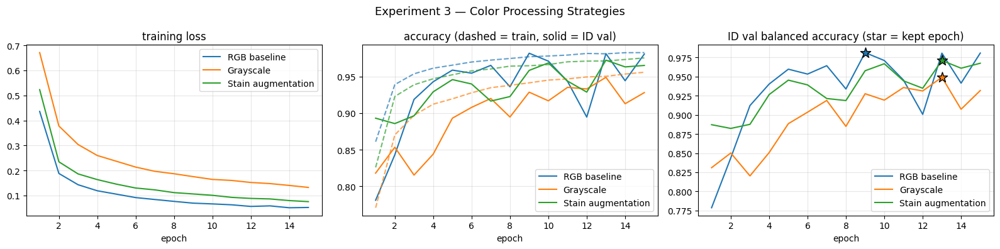

In [47]:
# Experiment 3 — Learning curves

plot_histories(
    {
        "RGB baseline": cnn_history,
        "Grayscale": gray_history,
        "Stain augmentation": stain_history
    },
    title="Experiment 3 — Color Processing Strategies"
)

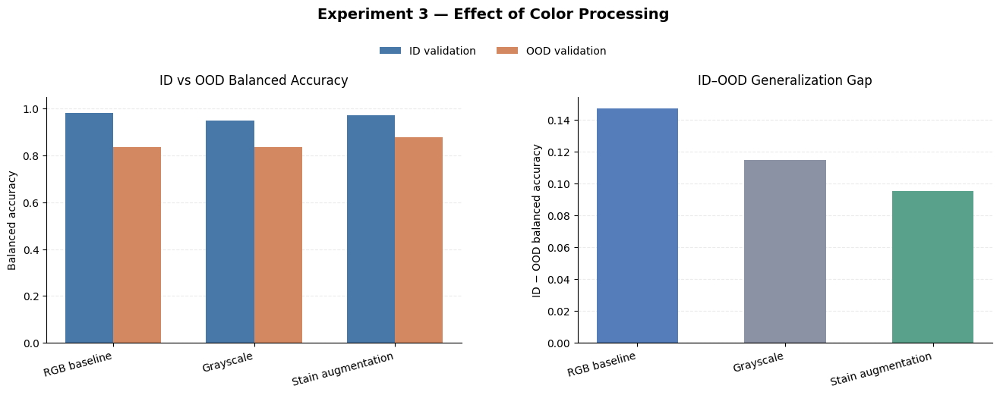

In [48]:
# Experiment 3 — ID/OOD balanced accuracy and generalization gap
# Improved layout with shared legend above both plots

short_names = ["RGB baseline", "Grayscale", "Stain augmentation"]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

x = np.arange(3)
width = 0.34

# --------------------------------------------------
# 1. ID and OOD balanced accuracy
# --------------------------------------------------

axes[0].bar(
    x - width / 2,
    exp3_results["id_bal_acc"],
    width,
    label="ID validation",
    color="#4878A8"
)

axes[0].bar(
    x + width / 2,
    exp3_results["ood_bal_acc"],
    width,
    label="OOD validation",
    color="#D38862"
)

axes[0].set_title(
    "ID vs OOD Balanced Accuracy",
    fontsize=12,
    pad=12
)

axes[0].set_ylabel("Balanced accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_names, rotation=15, ha="right")

# --------------------------------------------------
# 2. Generalization gap
# --------------------------------------------------

axes[1].bar(
    x,
    exp3_results["gap_bal_acc"],
    color=["#547DBA", "#8B92A4", "#59A18A"],
    width=0.55
)

axes[1].set_title(
    "ID–OOD Generalization Gap",
    fontsize=12,
    pad=12
)

axes[1].set_ylabel("ID − OOD balanced accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_names, rotation=15, ha="right")
axes[1].axhline(0, color="black", linewidth=0.8)

# --------------------------------------------------
# 3. Shared legend and formatting
# --------------------------------------------------

for ax in axes:
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Extract handles from the first subplot
handles, labels = axes[0].get_legend_handles_labels()

# One legend for the entire figure
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Experiment 3 — Effect of Color Processing",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

# Reserve space for the title and legend
fig.subplots_adjust(
    left=0.08,
    right=0.97,
    top=0.78,
    bottom=0.19,
    wspace=0.28
)

plt.show()

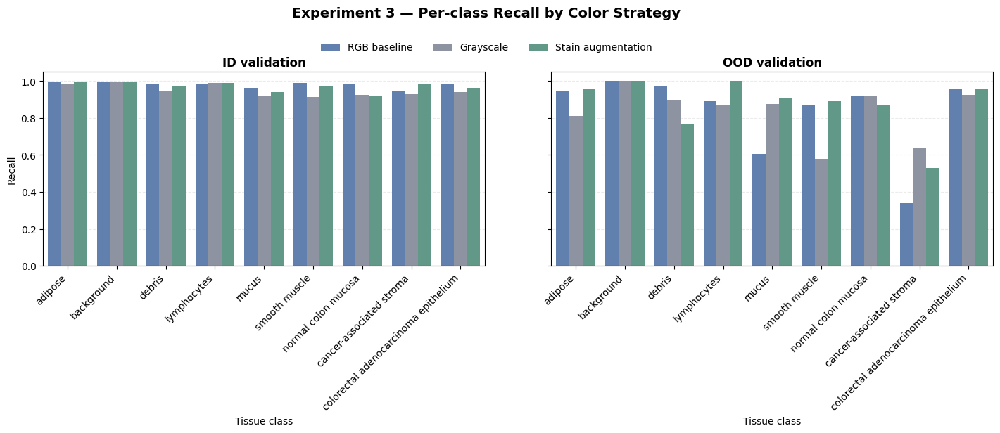

In [49]:
# Experiment 3 — Per-class recall comparison

from sklearn.metrics import recall_score
import seaborn as sns

exp3_models = {
    "RGB baseline": (cnn, rgb),
    "Grayscale": (cnn_gray, gray),
    "Stain augmentation": (cnn_stain, rgb)
}

recall_rows = []

for model_name, (model, preprocess) in exp3_models.items():
    for split in ["id_val", "ood_val"]:

        preds, labels = predict(
            model,
            make_loader(split),
            preprocess
        )

        recalls = recall_score(
            labels,
            preds,
            labels=np.arange(len(CLASSES)),
            average=None,
            zero_division=0
        )

        for c, recall in enumerate(recalls):
            recall_rows.append({
                "model": model_name,
                "split": split,
                "class": CLASSES[c],
                "recall": recall
            })

exp3_recall_df = pd.DataFrame(recall_rows)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharey=True
)

for ax, split in zip(axes, ["id_val", "ood_val"]):

    data = exp3_recall_df[
        exp3_recall_df["split"] == split
    ]

    sns.barplot(
        data=data,
        x="class",
        y="recall",
        hue="model",
        order=CLASSES,
        ax=ax,
        palette=["#547DBA", "#8B92A4", "#59A18A"],
        errorbar=None
    )

    ax.set_title(
        "ID validation" if split == "id_val"
        else "OOD validation",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Tissue class")
    ax.set_ylabel("Recall" if split == "id_val" else "")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    ax.get_legend().remove()

handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Experiment 3 — Per-class Recall by Color Strategy",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.84,
    bottom=0.38,
    wspace=0.15
)

plt.show()

### Design justification

> **Question.** (0.5 pt)
>
> Explain your experiment configuration: which CNN you started from, what remained the same and what changed. Why do
> the two strategies test whether the CNN relies on the exact colors, and what does each of them assume about the data?
> How does your experiment answer the question?

We used the **SmallCNN from Experiment 1** as our RGB baseline, without geometric augmentation, to isolate the effects of color processing. Both new models retained the same architecture (94,857 parameters), training data, batch size (128), Adam optimizer, learning rate (0.001), maximum number of epochs (15), and checkpoint selection based on ID validation balanced accuracy. The only intentional differences were the color-processing strategies.

The **grayscale model** was trained and evaluated using three identical grayscale channels, standardized with statistics from the grayscale training data. This removes chromatic information entirely, testing whether tissue morphology and intensity alone are sufficient for classification. In contrast, the **stain-augmented model** retained RGB inputs but randomly perturbed stain concentrations during training (`scale=0.2`, `shift=0.05`), while evaluation used unmodified RGB patches. This strategy assumes that exact stain colors may vary across centers while tissue morphology and useful staining relationships remain informative.

By comparing ID and OOD balanced accuracy, the generalization gap, learning curves, and per-class recall against the original RGB CNN, we can assess whether removing or randomizing color improves cross-center generalization. The experiment also examines the trade-off between suppressing center-specific color shortcuts and preserving diagnostically useful staining information.

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of removing and of randomizing the colors. Address the following points:
>
> Does each strategy improve or degrade the ID metrics? And the OOD metrics? Was this consistent with your hypothesis?
>
> Which classes gain or lose the most with each strategy? Can you attribute the results uniquely to color? Think
> about what else grayscale and stain augmentation change.
>
> How do the results connect with the Data Exploration you conducted?

**1. Overall Performance and Hypothesis Evaluation**

The results largely support our hypothesis that **stain augmentation provides a better balance between classification performance and cross-center robustness than grayscale conversion**. The original RGB CNN achieves 98.28% ID and 87.22% OOD balanced accuracy, with an 11.06-percentage-point gap. Grayscale decreases both metrics to approximately 94.5% ID and 84% OOD, although the gap narrows slightly to around 10.4 points. Stain augmentation preserves higher accuracy (approximately 96.7% ID and 88% OOD) and achieves the smallest gap, around 8.7 points. Thus, grayscale reduces reliance on color but sacrifices useful information, whereas stain augmentation modestly improves OOD performance while substantially narrowing the gap.

**2. Learning Curves and Regularization**

The learning curves reinforce these differences. The RGB baseline converges fastest and achieves the lowest training loss (approximately 0.05), followed by stain augmentation (0.08) and grayscale (0.13). Grayscale consistently exhibits lower training and validation accuracy, suggesting that removing chromatic information makes tissue discrimination more difficult. Stain augmentation introduces additional training variability, producing slightly higher loss and more fluctuating validation performance, but retains relatively high accuracy. Its smaller generalization gap is consistent with a regularization effect that discourages reliance on exact staining patterns.

**3. Per-Class Effects**

The impact of color processing varies substantially across tissue classes. On OOD validation, grayscale improves *adipose* recall (approximately 0.78 to 0.85) and *cancer-associated stroma* (0.56 to 0.67), but considerably reduces performance for *lymphocytes* (0.99 to 0.84) and *smooth muscle* (0.81 to 0.60). Stain augmentation produces particularly strong improvements for *adipose* (approximately 0.95) and *smooth muscle* (0.94), but reduces recall for *debris* (0.94 to 0.81) and *normal colon mucosa* (0.89 to 0.79). These class-dependent effects indicate that color is not uniformly helpful or harmful: some tissues benefit from chromatic information, while others are more affected by center-specific staining variations.

**4. Connection to EDA and Limitations**

These findings are consistent with our EDA, which revealed class-dependent RGB and HSV distribution shifts between centers, alongside partially stable structural features. The improved OOD performance and smaller gap with stain augmentation suggest that exact staining characteristics can contribute to domain-specific shortcuts, although this does not prove that the baseline CNN relied on them. Grayscale also changes luminance contrast and removes diagnostically useful distinctions between hematoxylin and eosin, while stain augmentation alters image appearance and acts as a regularizer. Therefore, the observed effects cannot be attributed exclusively to color dependence. Overall, **stain augmentation is the most effective strategy tested**, supporting the idea that preserving useful color information while reducing sensitivity to its precise appearance is preferable to removing color entirely.

---

## Experiment 4: Is the Gap Real, and Where Does It Come From?

Experiments 1-3 compared models trained with a single seed, and measured a single number for the gap. Two questions
remain before choosing a final model.

**Is a difference between two models larger than the noise of training?** The seed changes the initialization, the
order of the mini-batches and the augmentations. On distribution-shift benchmarks, the OOD performance of the same
configuration can change a lot from one seed to another: on Camelyon17, another histopathology task, the WILDS
benchmark reports 70.3 ± 6.4% OOD accuracy over 10 seeds. A difference between two models smaller than this
variation is not evidence of anything.

**Where does the gap come from?** The new center differs in the appearance of the patches (*covariate shift*), but
it may also have different proportions of the 9 classes (*label shift*). The two effects can be separated. Let
$r_{\text{ID}}(c)$ be the recall of class $c$ on `id_val`, and $\pi_{\text{OOD}}(c)$ the proportion of class $c$ in
`ood_val`. If only the proportions changed, and each class were recognized as well as in the ID validation, the OOD
accuracy would be

$$
\text{acc}_{\text{prop}} = \sum_{c=0}^{8} \pi_{\text{OOD}}(c)\, r_{\text{ID}}(c),
$$

and the accuracy gap splits into two terms:

$$
\underbrace{\text{acc}_{\text{ID}} - \text{acc}_{\text{OOD}}}_{\text{total gap}}
= \underbrace{\text{acc}_{\text{ID}} - \text{acc}_{\text{prop}}}_{\text{change of proportions}}
+ \underbrace{\text{acc}_{\text{prop}} - \text{acc}_{\text{OOD}}}_{\text{change of appearance}} .
$$

Steps:
1. **Seeds.** Retrain the MLP and the SmallCNN of Experiment 1, and the best variant of Experiment 2 and of
   Experiment 3 (chosen by ID validation balanced accuracy), with **at least 3 seeds** each (the seed used before
   counts as one). Report the mean and the standard deviation of the ID balanced accuracy, of the OOD balanced
   accuracy and of the gap.
2. **Decomposition.** Implement `gap_decomposition` and apply it to the SmallCNN of Experiment 1 and to your best
   variant.
3. **Final model.** Choose a final model using **only the ID validation**: one of the configurations above, or a new
   one that combines what worked (architecture, augmentations, the regularization tools of Lecture 18 such as dropout
   and weight decay, more epochs; you may also fine-tune a pretrained ResNet-18 from `torchvision.models`). Report its
   number of parameters and its training time, and evaluate it **once** on `ood_test`.

> **Question:**
>
> Are the differences between the models of Experiments 1-3 larger than the variation caused by the random seed? And
> is the ID–OOD gap of the CNN caused mainly by the change of class proportions or by the change of appearance of the
> patches?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis that answers both parts of the question: which of the comparisons of Experiments 1-3
> you expect to survive the variation between seeds, and which of the two terms of the decomposition you expect to
> dominate the gap of the CNN. Base the second prediction on your Data Exploration.*

We hypothesize that the **large performance gap between the MLP and the SmallCNN** observed in Experiment 1 will survive seed variation: across at least three seeds, the mean OOD balanced accuracy of the SmallCNN should remain substantially higher than that of the MLP, with the difference exceeding the standard deviation of either configuration. Likewise, we expect **stain augmentation (Experiment 3) to remain better than grayscale** under multiple seeds, because the single-seed margin in OOD balanced accuracy and in the ID–OOD gap was clear. In contrast, the **modest gains from symmetry augmentation (Experiment 2)**—on the order of about one percentage point in OOD balanced accuracy—may be comparable to seed noise, so that difference might shrink or disappear once mean ± std are reported.

For the decomposition of the CNN's accuracy gap, our Data Exploration showed both a change in class proportions between centers (for example, adipose and mucus become more frequent in `ood_val`, while debris and stroma become less frequent) and clear shifts in appearance (RGB/HSV distributions and texture-related signals differ by center). We therefore expect **both terms to be positive**, but we predict that the **change of appearance will dominate** the total accuracy gap of the SmallCNN: even after reweighting ID recalls by the OOD class proportions (`acc_prop`), the remaining drop to the true OOD accuracy should be the larger share. The proportions term should still be non-negligible and help explain why raw accuracy and balanced accuracy can move differently under label shift.

This hypothesis would be contradicted if (i) the MLP–CNN difference, or stain versus grayscale, becomes smaller than seed-to-seed variation, or if symmetry gains look large and stable under seeds; or (ii) the proportions term accounts for most of the CNN's accuracy gap, with appearance contributing little.

In [50]:
def run_seeds(build_model, build_optimizer, n_epochs: int, preprocess: Preprocess, augment=None,
              seeds=(42, 43, 44)) -> pd.DataFrame:
    # Trains the same configuration with several seeds and returns one row of metrics per seed.
    rows = []
    for s in seeds:
        torch.manual_seed(s)
        model = build_model().to(DEVICE)
        train = make_loader("train", batch_size=128, shuffle=True, shuffle_seed=s)
        fit(model, train, make_loader("id_val"), build_optimizer(model), n_epochs, preprocess, augment, verbose=False)
        id_m = evaluate(model, make_loader("id_val"), preprocess)
        ood_m = evaluate(model, make_loader("ood_val"), preprocess)
        rows.append({"seed": s, "id_bal_acc": id_m["bal_acc"], "ood_bal_acc": ood_m["bal_acc"],
                     "gap_bal_acc": id_m["bal_acc"] - ood_m["bal_acc"]})
        print(f"seed {s}: ID bal. acc {id_m['bal_acc']:.3f} | OOD bal. acc {ood_m['bal_acc']:.3f}")
    return pd.DataFrame(rows)


# Example (adapt to your configurations):
# seed_results = {
#     "SmallCNN (Exp. 1)": run_seeds(lambda: SmallCNN(), lambda m: optim.Adam(m.parameters(), lr=learning_rate),
#                                    n_epochs, rgb),
#     ...
# }
# seed_summary = pd.DataFrame({name: df.drop(columns="seed").agg(["mean", "std"]).unstack()
#                              for name, df in seed_results.items()}).T
# display(seed_summary)

In [51]:
def gap_decomposition(model: nn.Module, preprocess: Preprocess) -> dict[str, float]:
    # Splits the ID-OOD accuracy gap into a change of class proportions and a change of appearance.
    from sklearn.metrics import recall_score

    preds_id, y_id = predict(model, make_loader("id_val"), preprocess)
    preds_ood, y_ood = predict(model, make_loader("ood_val"), preprocess)

    acc_id = float((preds_id == y_id).mean())
    acc_ood = float((preds_ood == y_ood).mean())

    recall_id = recall_score(
        y_id, preds_id, labels=list(range(len(CLASSES))), average=None, zero_division=0
    )
    prop_ood = np.array([(y_ood == c).mean() for c in range(len(CLASSES))], dtype=float)

    acc_prop = float((prop_ood * recall_id).sum())

    return {
        "total_gap": acc_id - acc_ood,
        "proportions": acc_id - acc_prop,
        "appearance": acc_prop - acc_ood,
    }

for name, model, preprocess in [
    ("SmallCNN (Exp. 1)", cnn, rgb),
    ("SmallCNN + symmetry (Exp. 2)", cnn_aug, rgb),
    ("SmallCNN Stain Aug. (Exp. 3)", cnn_stain, rgb),
]:
    print(name, {k: round(v, 4) for k, v in gap_decomposition(model, preprocess).items()})

SmallCNN (Exp. 1) {'total_gap': 0.1238, 'proportions': -0.0015, 'appearance': 0.1253}
SmallCNN + symmetry (Exp. 2) {'total_gap': 0.0813, 'proportions': -0.002, 'appearance': 0.0833}
SmallCNN Stain Aug. (Exp. 3) {'total_gap': 0.0614, 'proportions': 0.0015, 'appearance': 0.0599}


In [52]:
seed_results = {
    "MLP (Exp. 1)": run_seeds(
        lambda: MLP(
            input_size=3 * 64 * 64,
            hidden_sizes=[512, 256],
            dropout=best_mlp_config["dropout"],
        ),
        lambda m: optim.Adam(m.parameters(), lr=best_mlp_config["learning_rate"]),
        n_epochs,
        rgb,
    ),
    "SmallCNN (Exp. 1)": run_seeds(
        lambda: SmallCNN(),
        lambda m: optim.Adam(m.parameters(), lr=best_cnn_config["learning_rate"]),
        n_epochs,
        rgb,
    ),
    "SmallCNN + symmetry (Exp. 2)": run_seeds(
        lambda: SmallCNN(),
        lambda m: optim.Adam(m.parameters(), lr=best_cnn_config["learning_rate"]),
        n_epochs,
        rgb,
        augment=random_symmetry,
    ),
    "SmallCNN Stain Aug. (Exp. 3)": run_seeds(
        lambda: SmallCNN(),
        lambda m: optim.Adam(m.parameters(), lr=best_cnn_config["learning_rate"]),
        n_epochs,
        rgb,
        augment=exp3_stain_jitter,
    ),
}
seed_summary = pd.DataFrame(
    {
        name: df.drop(columns="seed").agg(["mean", "std"]).unstack()
        for name, df in seed_results.items()
    }
).T
display(seed_summary)
# Optional: raw per-seed table
for name, df in seed_results.items():
    print(f"\n{name}")
    display(df)
final_name = (
    pd.Series({name: df["id_bal_acc"].mean() for name, df in seed_results.items()})
    .idxmax()
)
print("Modelo final (maior ID bal. acc média):", final_name)

seed 42: ID bal. acc 0.681 | OOD bal. acc 0.545
seed 43: ID bal. acc 0.674 | OOD bal. acc 0.554
seed 44: ID bal. acc 0.678 | OOD bal. acc 0.606
seed 42: ID bal. acc 0.981 | OOD bal. acc 0.834
seed 43: ID bal. acc 0.974 | OOD bal. acc 0.839
seed 44: ID bal. acc 0.982 | OOD bal. acc 0.819
seed 42: ID bal. acc 0.982 | OOD bal. acc 0.888
seed 43: ID bal. acc 0.967 | OOD bal. acc 0.784
seed 44: ID bal. acc 0.983 | OOD bal. acc 0.830
seed 42: ID bal. acc 0.971 | OOD bal. acc 0.876
seed 43: ID bal. acc 0.972 | OOD bal. acc 0.870
seed 44: ID bal. acc 0.976 | OOD bal. acc 0.911


id_bal_acc           ood_bal_acc            \
                                   mean       std        mean       std   
MLP (Exp. 1)                   0.678031  0.003442    0.568238  0.032988   
SmallCNN (Exp. 1)              0.979175  0.004302    0.830834  0.010472   
SmallCNN + symmetry (Exp. 2)   0.977370  0.008755    0.833813  0.051915   
SmallCNN Stain Aug. (Exp. 3)   0.972802  0.002554    0.885425  0.022253   

                             gap_bal_acc            
                                    mean       std  
MLP (Exp. 1)                    0.109793  0.033302  
SmallCNN (Exp. 1)               0.148342  0.013943  
SmallCNN + symmetry (Exp. 2)    0.143556  0.045455  
SmallCNN Stain Aug. (Exp. 3)    0.087377  0.019763


MLP (Exp. 1)


,seed,id_bal_acc,ood_bal_acc,gap_bal_acc
0,42,0.681240,0.544562,0.136677
1,43,0.674395,0.554233,0.120161
2,44,0.678458,0.605917,0.072541



SmallCNN (Exp. 1)


,seed,id_bal_acc,ood_bal_acc,gap_bal_acc
0,42,0.981415,0.834143,0.147272
1,43,0.974215,0.839251,0.134964
2,44,0.981895,0.819106,0.162789



SmallCNN + symmetry (Exp. 2)


,seed,id_bal_acc,ood_bal_acc,gap_bal_acc
0,42,0.981612,0.887644,0.093968
1,43,0.967301,0.784054,0.183248
2,44,0.983195,0.829742,0.153453



SmallCNN Stain Aug. (Exp. 3)


,seed,id_bal_acc,ood_bal_acc,gap_bal_acc
0,42,0.971148,0.875786,0.095362
1,43,0.971516,0.869618,0.101898
2,44,0.975743,0.910873,0.064871


Modelo final (maior ID bal. acc média): SmallCNN (Exp. 1)


In [53]:
# OOD test: run this cell only once, after all decisions are made. The SmallCNN of Experiment 1 is evaluated as a
# reference.
for name in dict.fromkeys([final_name, "SmallCNN (Exp. 1)"]):
    model, preprocess = MODELS[name]
    test = evaluate(model, make_loader("ood_test"), preprocess)
    RESULTS[name].update(test_acc=test["acc"], test_bal_acc=test["bal_acc"])
    print(f"{name}: OOD test acc {test['acc']:.3f} | OOD test bal. acc {test['bal_acc']:.3f}")

SmallCNN (Exp. 1): OOD test acc 0.874 | OOD test bal. acc 0.854


### Discussion: seeds and decomposition

> **Question.** (1.0 pt)
>
> Do the results support or contradict your hypothesis? Refer to specific numbers.
>
> Which conclusions of Experiments 1-3 survive the variation between seeds, and which should be revised?
>
> How is the gap of the CNN divided between the change of proportions and the change of appearance? What does the
> decomposition say about the difference between the accuracy and the balanced accuracy, and about which kind of
> intervention (architecture, augmentation, color) can reduce each term?

*YOUR ANSWER HERE*

### Discussion: final model

> **Question.** (1.0 pt)
>
> What is your final model, how many parameters does it have, and how long did it take to train? Compare it with the
> previous models and draw a link with the results.
>
> How does its performance on `ood_test` compare with its performance on `ood_val`, and with the SmallCNN of
> Experiment 1? Did the gap shrink?
>
> If your results are positive, can you attribute with certainty which change contributed most? Conversely, if they
> are negative, provide an alternative explanation that is consistent with the failure.

*YOUR ANSWER HERE*

---

## Summary

Complete the table below with the results of your experiments. The seed column comes from Experiment 4, and the
test columns are filled in only for the two models evaluated on `ood_test`.

| Model | Parameters | Training time (s) | ID val bal. acc | OOD val bal. acc | Gap (bal. acc) | OOD val bal. acc over seeds (mean ± std) | OOD test bal. acc | OOD test acc |
|---|---|---|---|---|---|---|---|---|
| MLP (Exp. 1) | | | | | | | – | – |
| SmallCNN (Exp. 1) | | | | | | | | |
| MLP + symmetries (Exp. 2) | | | | | | | – | – |
| SmallCNN + symmetries (Exp. 2) | | | | | | | – | – |
| SmallCNN, grayscale (Exp. 3) | | | | | | | – | – |
| SmallCNN + stain augmentation (Exp. 3) | | | | | | | – | – |
| Final model (Exp. 4): *name* | | | | | | | | |

*Gap = ID val balanced accuracy − OOD val balanced accuracy. Leave the seed column empty for the configurations you
did not retrain.*

---

## References

- J. N. Kather et al. *Predicting survival from colorectal cancer histology slides using deep learning: A
  retrospective multicenter study.* PLOS Medicine, 2019.
- J. Yang et al. *MedMNIST v2 - A large-scale lightweight benchmark for 2D and 3D biomedical image classification.*
  Scientific Data, 2023.
- D. Tellez et al. *Quantifying the effects of data augmentation and stain color normalization in convolutional
  neural networks for computational pathology.* Medical Image Analysis, 2019.
- P. W. Koh et al. *WILDS: A Benchmark of in-the-Wild Distribution Shifts.* ICML, 2021.

---

## Assignment Submission

This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.

Before submitting, verify that:
- The notebook runs end-to-end without errors (use **Run All** after restarting the kernel).
- All plots are rendered in the output.
- All written sections (Hypothesis, Design, Discussion) are filled in.
- The Summary table is completed.
- AI usage declaration and prompts are included, if applicable.

**Important: Only one member of the group should submit.**

### Policy for late submissions

You are NOT encouraged to submit after the deadline; however, in this case the following penalties apply:

- 25% deduction for 1-day late submission.
- 50% deduction for 2-day late submission.
- 75% deduction for 3-day late submission.